<a href="https://colab.research.google.com/github/Derri12345/bitcoin-forecasting/blob/main/50%3A50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipython-input-2350181638.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("BTC-USD" , start = "2014-10-01",  interval = '1d')
[*********************100%***********************]  1 of 1 completed


/tmp/ipython-input-2350181638.py:16: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipython-input-2350181638.py:53: UserWarning:

This axis already has a converter set and is updating to a potentially incompatible converter

/tmp/ipython-input-2350181638.py:16: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed


ValueError: If using all scalar values, you must pass an index

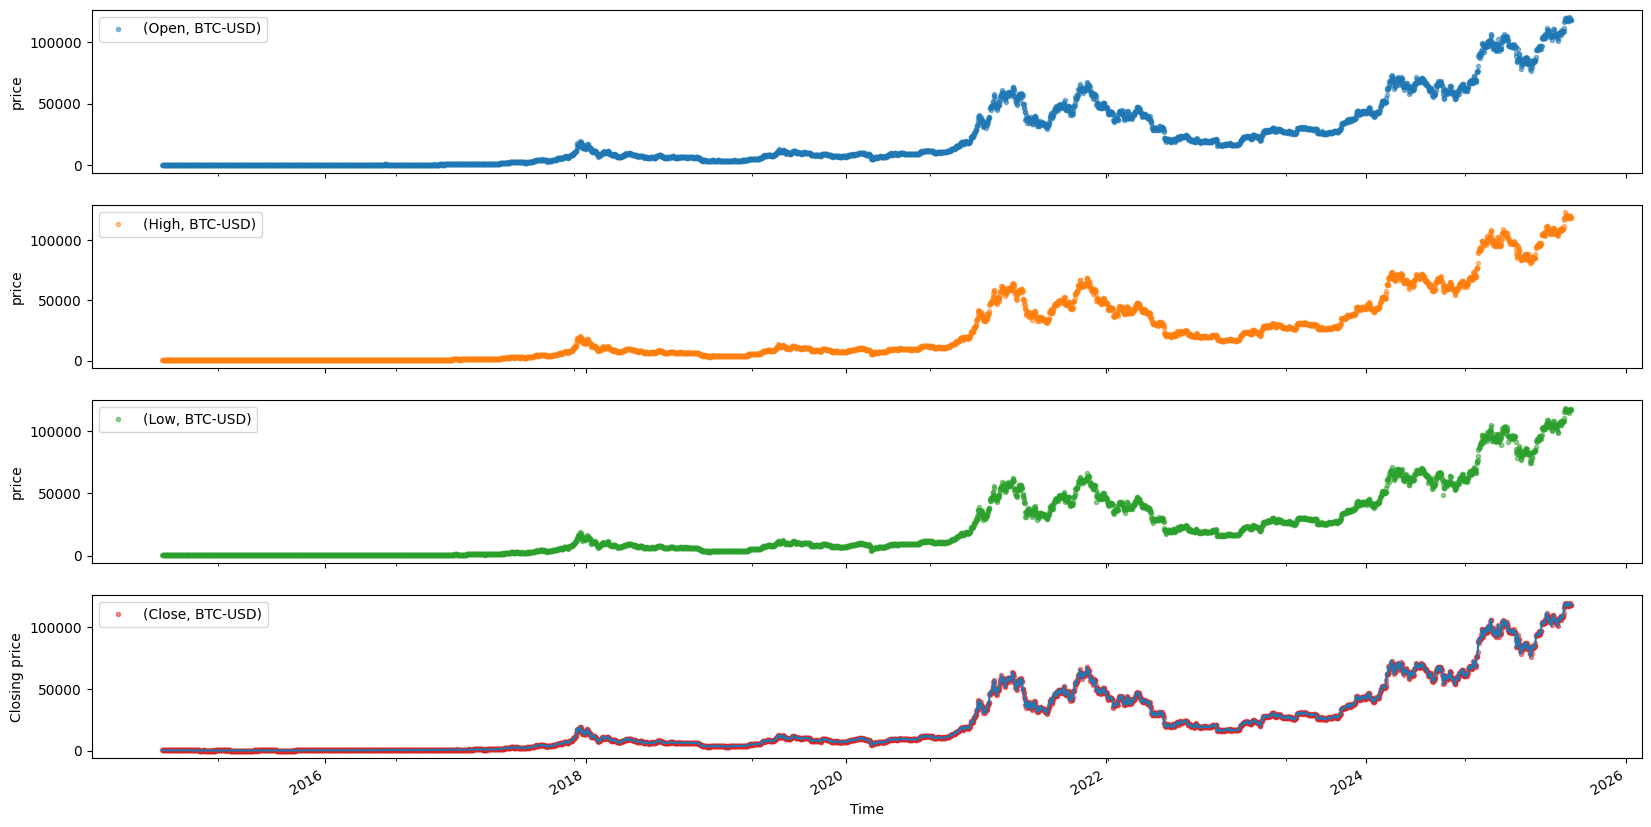

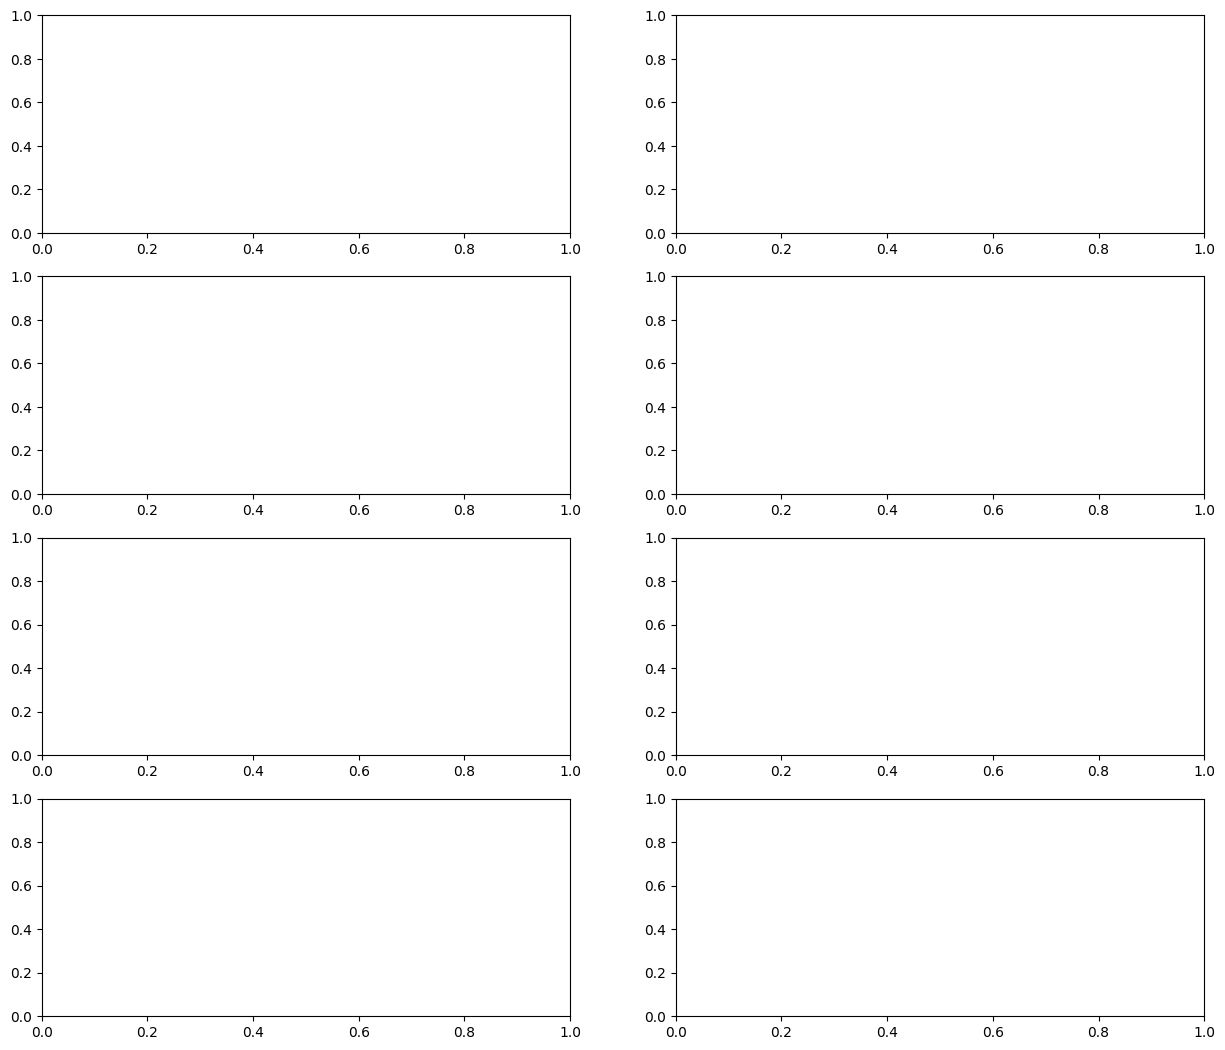

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.callbacks import ModelCheckpoint , ReduceLROnPlateau
from tensorflow.python.keras.layers.legacy_rnn.rnn_cell_impl import BasicLSTMCell
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Dropout , LSTM , Bidirectional , BatchNormalization, GRU, Embedding
from sklearn.metrics import mean_squared_error, median_absolute_error,mean_absolute_percentage_error,r2_score
import math
import plotly.graph_objects as go

def load_data():
    data = yf.download("BTC-USD" , start = "2014-10-01",  interval = '1d')
    #data = yf.download("^GSPC" , start = "2014-10-01",  interval = '1d')
    #data = yf.download("^AMX" , start = "2014-10-01",  interval = '1d')

    #data.head(3)
    # Sort the data points based on indexes just for confirmation
    data.sort_index(inplace = True)

    # Remove any duplicate index
    data = data.loc[~data.index.duplicated(keep='first')]

    # Check for missing values
    data.isnull().sum()

    return data

def data_desc():
    data  = load_data()
    # Get the statistics of the data
    data.describe()

    # Check the trend in Closing Values
    fig = go.Figure()

    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines'))
    fig.update_layout(height=500, width=900,
                      xaxis_title='Date', yaxis_title='Close')
    fig.show()

    cols_plot = ['Open', 'High', 'Low', 'Close']
    axes = data[cols_plot].plot(marker='.', alpha=0.5, linestyle='None', figsize=(20, 11), subplots=True)
    for ax in axes:
        ax.set_ylabel('price')

def plt_params():
    data = load_data()
    plt.rcParams["figure.figsize"] = (15, 8)
    plt.plot(data['Close'], label="Close price")
    plt.xlabel("Time")
    plt.ylabel("Closing price")

def data_distribution():
    data = load_data()
    fig, ax = plt.subplots(4, 2, figsize=(15, 13))
    sns.boxplot(x=data["Close"], ax=ax[0, 0])
    sns.distplot(data['Close'], ax=ax[0, 1])
    sns.boxplot(x=data["Open"], ax=ax[1, 0])
    sns.distplot(data['Open'], ax=ax[1, 1])
    sns.boxplot(x=data["High"], ax=ax[2, 0])
    sns.distplot(data['High'], ax=ax[2, 1])
    sns.boxplot(x=data["Low"], ax=ax[3, 0])
    sns.distplot(data['Low'], ax=ax[3, 1])
    plt.tight_layout()

def cor_matrix():
    data = load_data()
    plt.figure(figsize=(10, 6))
    sns.heatmap(data.corr(), cmap=plt.cm.Blues, annot=True)
    plt.title('correlation between prices',
              fontsize=13)
    plt.show()


if __name__ == '__main__':
    data_desc()
    plt_params()
    data_distribution()
    cor_matrix()

In [ ]:
!pip install TA-Lib
import yfinance as yf
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.callbacks import ModelCheckpoint , ReduceLROnPlateau
from tensorflow.python.keras.layers.legacy_rnn.rnn_cell_impl import BasicLSTMCell
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Dropout , LSTM , Bidirectional , BatchNormalization, GRU, Embedding
from sklearn.metrics import mean_squared_error, median_absolute_error,mean_absolute_percentage_error,r2_score
import math
import plotly.graph_objects as go
from sklearn.preprocessing import MinMaxScaler
import pickle
from tqdm.notebook import tnrange
import talib
from data.data import *
from data.preprocess import *

class MultiDimensionScaler():
    def __init__(self):
        self.scalers = []

    def fit_transform(self , X):
        total_dims = X.shape[2]
        for i in range(total_dims):
            Scaler = MinMaxScaler()
            X[:, :, i] = Scaler.fit_transform(X[:,:,i])
            self.scalers.append(Scaler)
        return X

    def transform(self , X):
        for i in range(X.shape[2]):
            X[:, :, i] = self.scalers[i].transform(X[:,:,i])
        return X
def CreateFeatures_and_Targets(data, feature_length):
    X = []
    Y = []

    for i in tnrange(len(data) - feature_length):
        X.append(data.iloc[i : i + feature_length,:].values)
        Y.append(data["Close"].values[i+feature_length])

    X = np.array(X)
    Y = np.array(Y)

    return X , Y

def save_object(obj , name : str):
    pickle_out = open(f"{name}.pck","wb")
    pickle.dump(obj, pickle_out)
    pickle_out.close()

def load_object(name : str):
    pickle_in = open(f"{name}.pck","rb")
    data = pickle.load(pickle_in)
    return data

if __name__ == '__main__':
    data = technical_indicator()
    X, Y = CreateFeatures_and_Targets(data, 32)
    Xtrain, Xtest, Ytrain, Ytest = X[:-test_length], X[-test_length:], Y[:-test_length], Y[-test_length:]

    Feature_Scaler = MultiDimensionScaler()
    Xtrain = Feature_Scaler.fit_transform(Xtrain)
    Xtest = Feature_Scaler.transform(Xtest)

    Target_Scaler = MinMaxScaler()
    Ytrain = Target_Scaler.fit_transform(Ytrain.reshape(-1, 1))
    Ytest = Target_Scaler.transform(Ytest.reshape(-1, 1))

    # Save your objects for future purposes
    save_object(Feature_Scaler, "Feature_Scaler")
    save_object(Target_Scaler, "Target_Scaler")

  Using cached setuptools-80.9.0-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 19.3 MB/s eta 0:00:00
Using cached setuptools-80.9.0-py3-none-any.whl (1.2 MB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 75.2.0
    Uninstalling setuptools-75.2.0:
      Successfully uninstalled setuptools-75.2.0
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.


  Using cached ta_lib-0.6.4.tar.gz (381 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done






  Installing backend dependencies ... canceledERROR: Operation cancelled by user


ModuleNotFoundError: No module named 'talib'

In [ ]:
!pip install pandas-ta
import yfinance as yf
import numpy as np
import pandas as pd
import pandas_ta as ta  # ⬅ Gantikan talib
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.python.keras.layers.legacy_rnn.rnn_cell_impl import BasicLSTMCell
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, BatchNormalization, GRU, Embedding
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
import math
import plotly.graph_objects as go

def load_data():
    data = yf.download("BTC-USD", start="2014-10-01", interval='1d')

    data.sort_index(inplace=True)
    data = data.loc[~data.index.duplicated(keep='first')]
    data = data.dropna()

    # ⬇ Tambah indikator teknikal (contoh: RSI, MACD)
    data['RSI'] = ta.rsi(data['Close'], length=14)
    macd = ta.macd(data['Close'])
    data = pd.concat([data, macd], axis=1)

    return data

def data_desc():
    data = load_data()
    data.describe()

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines'))
    fig.update_layout(height=500, width=900,
                      xaxis_title='Date', yaxis_title='Close')
    fig.show()

    cols_plot = ['Open', 'High', 'Low', 'Close']
    axes = data[cols_plot].plot(marker='.', alpha=0.5, linestyle='None', figsize=(20, 11), subplots=True)
    for ax in axes:
        ax.set_ylabel('price')

def plt_params():
    data = load_data()
    plt.rcParams["figure.figsize"] = (15, 8)
    plt.plot(data['Close'], label="Close price")
    plt.xlabel("Time")
    plt.ylabel("Closing price")

def data_distribution():
    data = load_data()
    fig, ax = plt.subplots(4, 2, figsize=(15, 13))
    sns.boxplot(x=data["Close"], ax=ax[0, 0])
    sns.histplot(data['Close'], ax=ax[0, 1], kde=True)
    sns.boxplot(x=data["Open"], ax=ax[1, 0])
    sns.histplot(data['Open'], ax=ax[1, 1], kde=True)
    sns.boxplot(x=data["High"], ax=ax[2, 0])
    sns.histplot(data['High'], ax=ax[2, 1], kde=True)
    sns.boxplot(x=data["Low"], ax=ax[3, 0])
    sns.histplot(data['Low'], ax=ax[3, 1], kde=True)
    plt.tight_layout()

def cor_matrix():
    data = load_data()
    plt.figure(figsize=(10, 6))
    sns.heatmap(data.corr(), cmap=plt.cm.Blues, annot=True)
    plt.title('Correlation between prices', fontsize=13)
    plt.show()

if __name__ == '__main__':
    data_desc()
    plt_params()
    data_distribution()
    cor_matrix()


  Preparing metadata (setup.py) ... done
  DEPRECATION: Building 'pandas-ta' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'pandas-ta'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  Created wheel for pandas-ta: filename=pandas_ta-0.3.14b0-py3-none-any.whl size=218984 sha256=da6ce27f71069119bdb45970b5945d02fe22d2293a9ca16f767f40099323ce37
  Stored in directory: /root/.cache/pip/wheels/7f/33/8b/50b245c5c65433cd8f5cb24ac15d97e5a3db2d41a8b6ae957d
Successfully built pandas-ta


/usr/local/lib/python3.11/dist-packages/pandas_ta/__init__.py:7: UserWarning:

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.



ImportError: cannot import name 'NaN' from 'numpy' (/usr/local/lib/python3.11/dist-packages/numpy/__init__.py)

In [ ]:

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Fungsi ambil data dan tambah indikator teknikal
def load_data_with_indicators():
    data = yf.download("BTC-USD", start="2014-10-01", interval='1d')
    data.sort_index(inplace=True)
    data = data.loc[~data.index.duplicated(keep='first')]
    data.dropna(inplace=True)

    # Tambah indikator teknikal
    data['RSI'] = ta.rsi(data['Close'], length=14)
    data['SMA_50'] = ta.sma(data['Close'], length=50)
    data['SMA_200'] = ta.sma(data['Close'], length=200)

    macd = ta.macd(data['Close'])
    data = pd.concat([data, macd], axis=1)

    return data.dropna()

# Statistik deskriptif dan tren harga
def data_desc():
    data = load_data_with_indicators()
    print(data.describe())

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines', name='Close'))
    fig.add_trace(go.Scatter(x=data.index, y=data['SMA_50'], mode='lines', name='SMA 50'))
    fig.add_trace(go.Scatter(x=data.index, y=data['SMA_200'], mode='lines', name='SMA 200'))
    fig.update_layout(title='BTC-USD Closing Price & Moving Averages',
                      xaxis_title='Date', yaxis_title='Price (USD)',
                      width=900, height=500)
    fig.show()

    return data

# Boxplot & distribusi histogram
def data_distribution():
    data = load_data_with_indicators()
    fig, ax = plt.subplots(4, 2, figsize=(15, 13))
    sns.boxplot(x=data["Close"], ax=ax[0, 0])
    sns.histplot(data["Close"], ax=ax[0, 1], kde=True)
    sns.boxplot(x=data["Open"], ax=ax[1, 0])
    sns.histplot(data["Open"], ax=ax[1, 1], kde=True)
    sns.boxplot(x=data["High"], ax=ax[2, 0])
    sns.histplot(data["High"], ax=ax[2, 1], kde=True)
    sns.boxplot(x=data["Low"], ax=ax[3, 0])
    sns.histplot(data["Low"], ax=ax[3, 1], kde=True)
    plt.tight_layout()
    plt.show()

# Korelasi antar fitur
def cor_matrix():
    data = load_data_with_indicators()
    plt.figure(figsize=(12, 6))
    sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
    plt.title("Correlation Matrix")
    plt.show()

# Plot parameter dasar
def plt_params():
    data = load_data_with_indicators()
    plt.figure(figsize=(15, 8))
    plt.plot(data['Close'], label='Close Price')
    plt.xlabel('Time')
    plt.ylabel('Closing Price')
    plt.title('BTC Closing Price')
    plt.legend()
    plt.grid(True)
    plt.show()

# Eksekusi fungsi utama
if __name__ == '__main__':
    data_desc()
    plt_params()
    data_distribution()
    cor_matrix()


/tmp/ipython-input-1828640796.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("BTC-USD", start="2014-10-01", interval='1d')
[*********************100%***********************]  1 of 1 completed


NameError: name 'ta' is not defined

[*********************100%***********************]  1 of 1 completed


Descriptive Statistics:
 Price           Close           High            Low           Open  \
Ticker        BTC-USD        BTC-USD        BTC-USD        BTC-USD   
count     3956.000000    3956.000000    3956.000000    3956.000000   
mean     23878.957235   24355.783143   23324.311881   23850.222570   
std      28045.627511   28538.760605   27466.430851   28008.817536   
min        178.102997     211.731003     171.509995     176.897003   
25%       2486.622559    2557.549988    2375.547546    2489.062561   
50%      10180.006836   10386.951172    9864.953125   10176.371582   
75%      38122.640625   39312.143555   37110.909180   38104.682617   
max     119995.414062  123091.609375  118959.195312  119997.445312   

Price         Volume  
Ticker       BTC-USD  
count   3.956000e+03  
mean    2.017305e+10  
std     2.146977e+10  
min     5.914570e+06  
25%     1.072115e+09  
50%     1.633667e+10  
75%     3.153834e+10  
max     3.509679e+11  


[*********************100%***********************]  1 of 1 completed


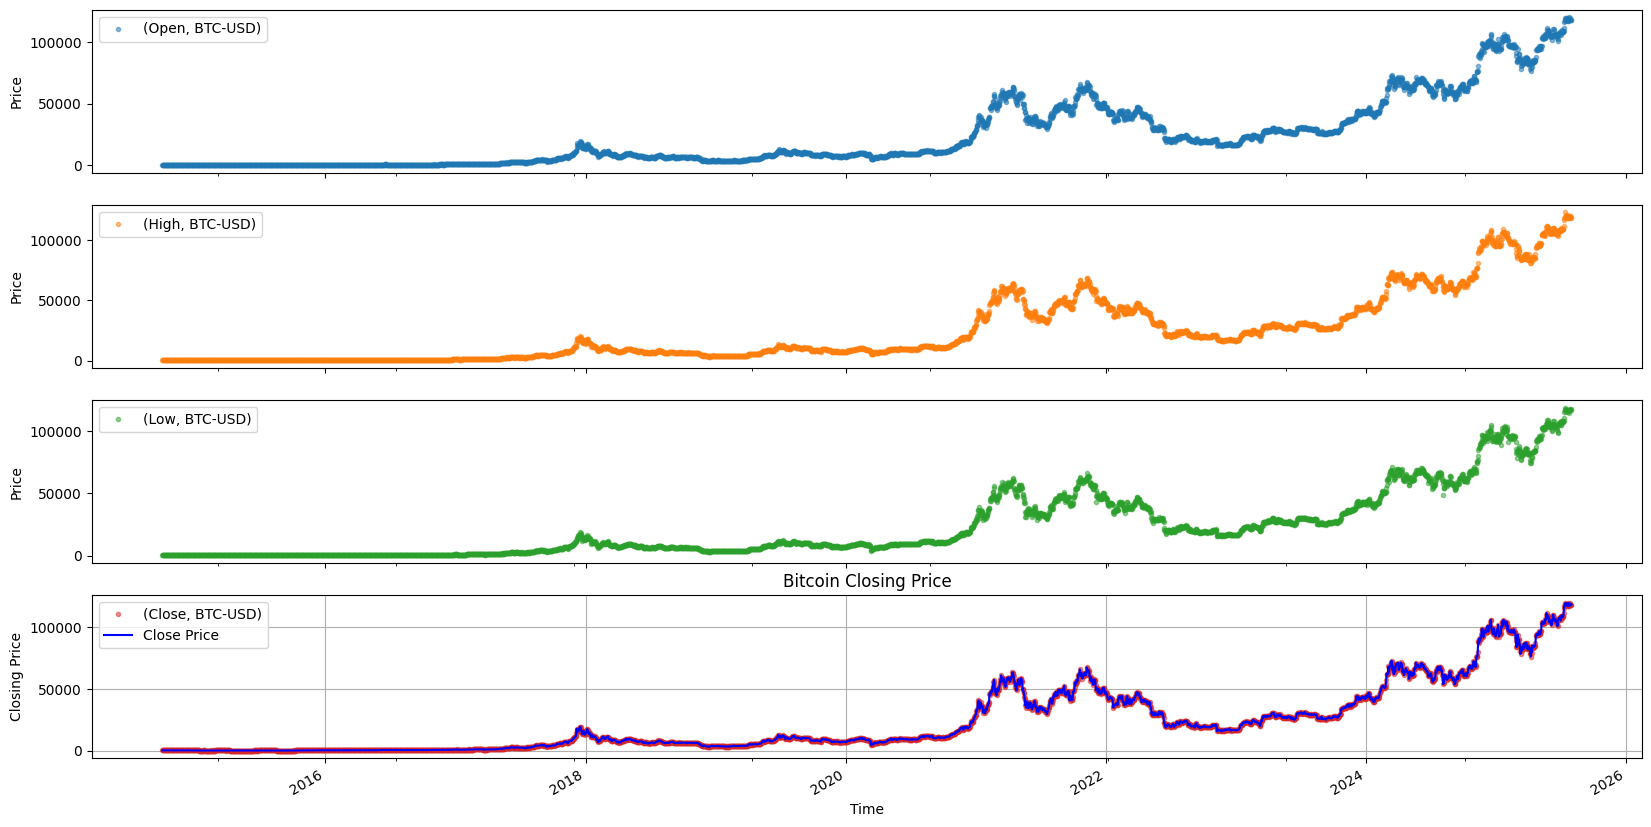

[*********************100%***********************]  1 of 1 completed


ValueError: If using all scalar values, you must pass an index

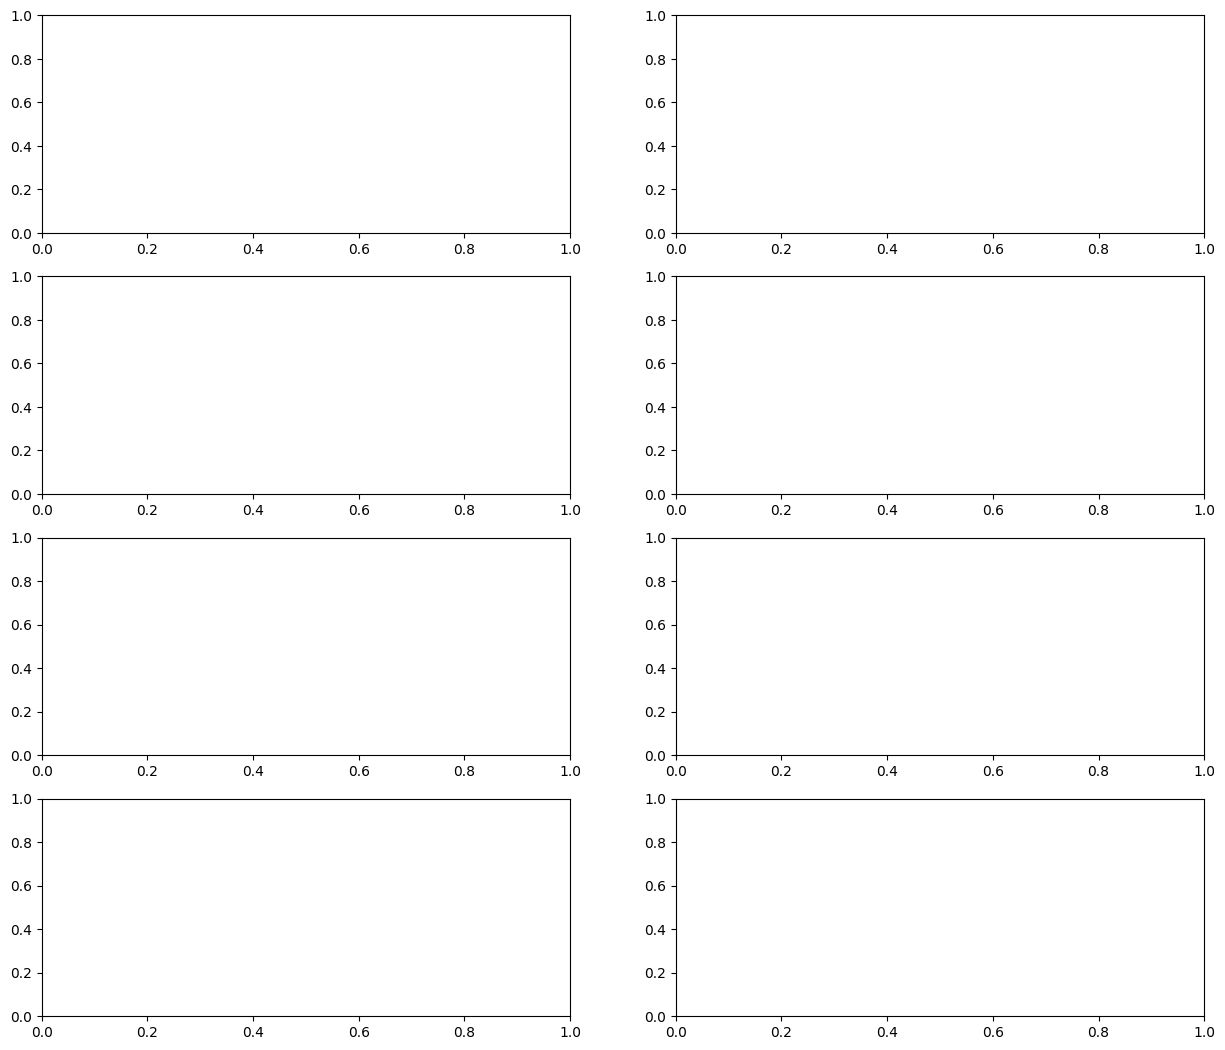

In [ ]:
# === Import libraries ===
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, BatchNormalization, GRU, Embedding

from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score

import warnings
warnings.filterwarnings("ignore")

# === Function to load Bitcoin data ===
def load_data():
    data = yf.download("BTC-USD", start="2014-10-01", interval='1d')

    data.sort_index(inplace=True)
    data = data.loc[~data.index.duplicated(keep='first')]

    return data

# === Descriptive plot and line chart ===
def data_desc():
    data = load_data()

    # Show descriptive statistics
    print("Descriptive Statistics:\n", data.describe())

    # Interactive Plotly Close Price
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines', name='BTC Close Price'))
    fig.update_layout(height=500, width=900, title='Bitcoin Close Price Over Time',
                      xaxis_title='Date', yaxis_title='Close')
    fig.show()

    # Matplotlib plot of OHLC
    cols_plot = ['Open', 'High', 'Low', 'Close']
    axes = data[cols_plot].plot(marker='.', alpha=0.5, linestyle='None',
                                figsize=(20, 11), subplots=True)
    for ax in axes:
        ax.set_ylabel('Price')

# === Line plot for closing price ===
def plt_params():
    data = load_data()
    plt.rcParams["figure.figsize"] = (15, 8)
    plt.plot(data['Close'], label="Close Price", color='blue')
    plt.xlabel("Time")
    plt.ylabel("Closing Price")
    plt.title("Bitcoin Closing Price")
    plt.legend()
    plt.grid(True)
    plt.show()

# === Data distribution plot using Seaborn ===
def data_distribution():
    data = load_data()
    fig, ax = plt.subplots(4, 2, figsize=(15, 13))

    sns.boxplot(x=data["Close"], ax=ax[0, 0])
    sns.histplot(data['Close'], kde=True, ax=ax[0, 1])

    sns.boxplot(x=data["Open"], ax=ax[1, 0])
    sns.histplot(data['Open'], kde=True, ax=ax[1, 1])

    sns.boxplot(x=data["High"], ax=ax[2, 0])
    sns.histplot(data['High'], kde=True, ax=ax[2, 1])

    sns.boxplot(x=data["Low"], ax=ax[3, 0])
    sns.histplot(data['Low'], kde=True, ax=ax[3, 1])

    plt.tight_layout()
    plt.show()

# === Correlation Matrix ===
def cor_matrix():
    data = load_data()
    plt.figure(figsize=(10, 6))
    sns.heatmap(data.corr(), cmap='Blues', annot=True)
    plt.title('Correlation Between Bitcoin Price Features', fontsize=13)
    plt.show()

# === Main ===
if __name__ == '__main__':
    data_desc()
    plt_params()
    data_distribution()
    cor_matrix()


[*********************100%***********************]  1 of 1 completed

Statistik Data:
 Price           Close           High            Low           Open  \
Ticker        BTC-USD        BTC-USD        BTC-USD        BTC-USD   
count     3956.000000    3956.000000    3956.000000    3956.000000   
mean     23878.960480   24355.783143   23324.311881   23850.222570   
std      28045.638462   28538.760605   27466.430851   28008.817536   
min        178.102997     211.731003     171.509995     176.897003   
25%       2486.622559    2557.549988    2375.547546    2489.062561   
50%      10180.006836   10386.951172    9864.953125   10176.371582   
75%      38122.640625   39312.143555   37110.909180   38104.682617   
max     119995.414062  123091.609375  118959.195312  119997.445312   

Price         Volume  
Ticker       BTC-USD  
count   3.956000e+03  
mean    2.017281e+10  
std     2.146922e+10  
min     5.914570e+06  
25%     1.072115e+09  
50%     1.633667e+10  
75%     3.153834e+10  
max     3.509679e+11  


[*********************100%***********************]  1 of 1 completed


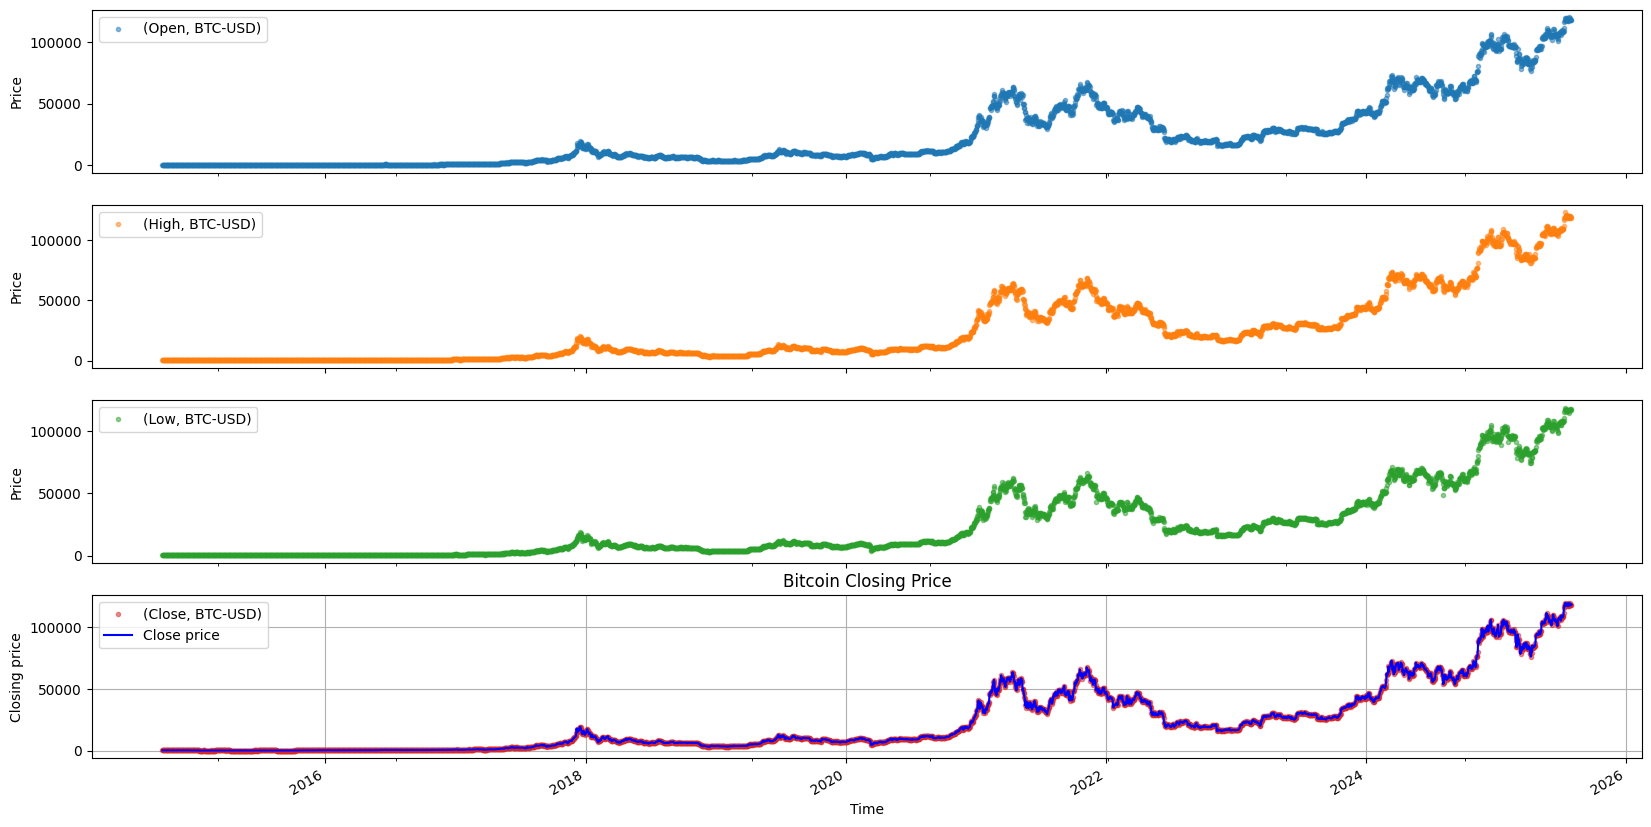

[*********************100%***********************]  1 of 1 completed


Terjadi kesalahan: If using all scalar values, you must pass an index


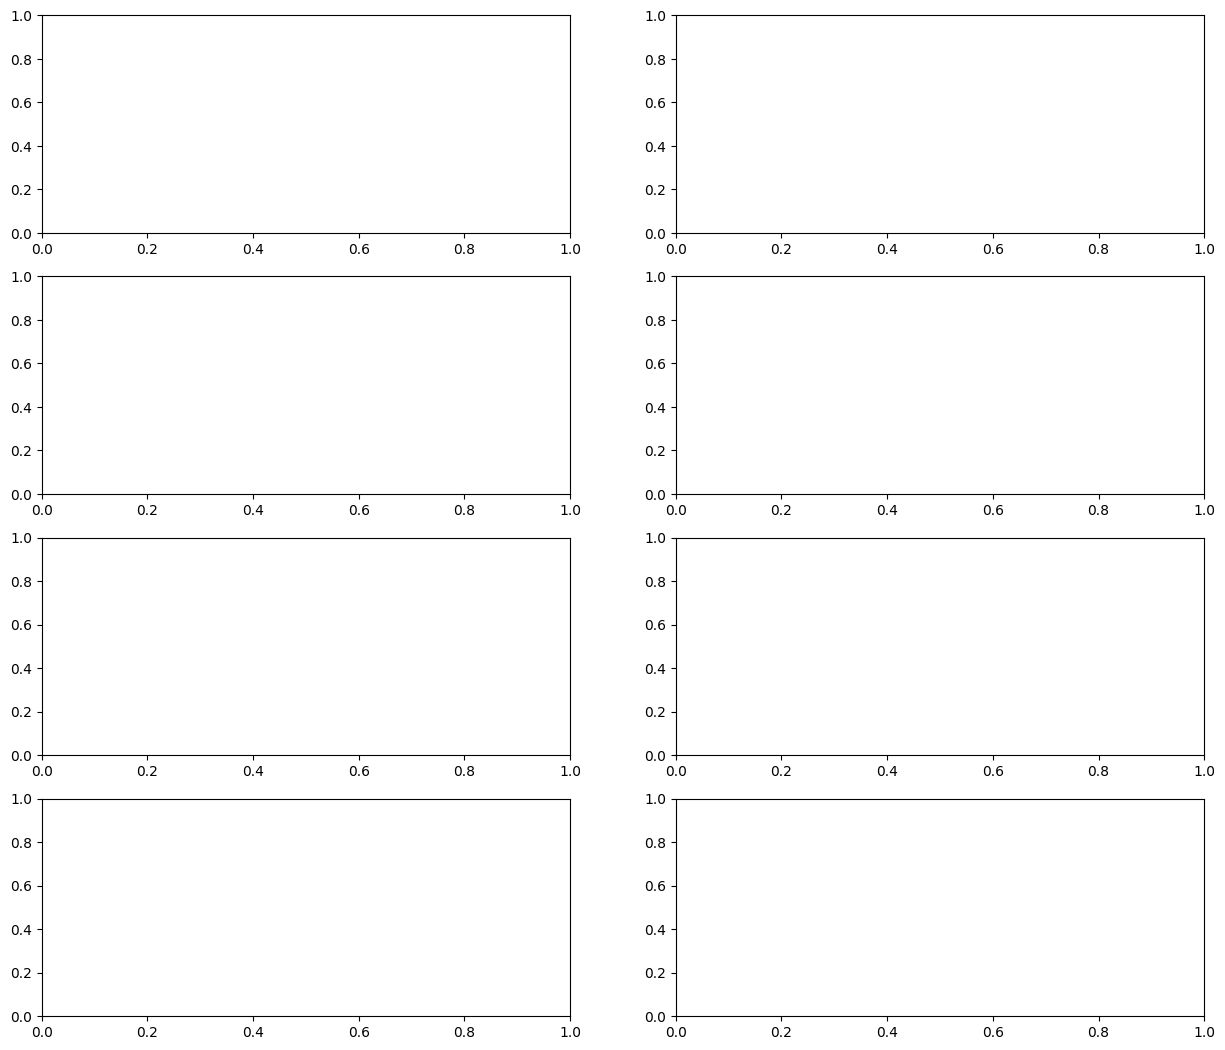

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, BatchNormalization, GRU, Embedding
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
import plotly.graph_objects as go

# Fungsi untuk mengambil data
def load_data():
    data = yf.download("BTC-USD", start="2014-10-01", interval='1d')

    # Cek jika data kosong
    if data.empty:
        raise ValueError("Data download failed: DataFrame is empty. Periksa koneksi internet atau ticker.")

    data.sort_index(inplace=True)
    data = data.loc[~data.index.duplicated(keep='first')]
    return data

# Deskripsi dan visualisasi awal data
def data_desc():
    data = load_data()

    print("Statistik Data:\n", data.describe())

    # Plot harga penutupan (Close)
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines', name='Close Price'))
    fig.update_layout(title='BTC-USD Close Price Trend', height=500, width=900,
                      xaxis_title='Date', yaxis_title='Close')
    fig.show()

    # Plot semua harga utama
    cols_plot = ['Open', 'High', 'Low', 'Close']
    axes = data[cols_plot].plot(marker='.', alpha=0.5, linestyle='None', figsize=(20, 11), subplots=True)
    for ax in axes:
        ax.set_ylabel('Price')

# Visualisasi garis tren harga penutupan
def plt_params():
    data = load_data()
    plt.rcParams["figure.figsize"] = (15, 8)
    plt.plot(data['Close'], label="Close price", color='blue')
    plt.xlabel("Time")
    plt.ylabel("Closing price")
    plt.title("Bitcoin Closing Price")
    plt.legend()
    plt.grid(True)
    plt.show()

# Distribusi data harga
def data_distribution():
    data = load_data()

    fig, ax = plt.subplots(4, 2, figsize=(15, 13))
    sns.boxplot(x=data["Close"], ax=ax[0, 0])
    sns.histplot(data['Close'], ax=ax[0, 1], kde=True)

    sns.boxplot(x=data["Open"], ax=ax[1, 0])
    sns.histplot(data['Open'], ax=ax[1, 1], kde=True)

    sns.boxplot(x=data["High"], ax=ax[2, 0])
    sns.histplot(data['High'], ax=ax[2, 1], kde=True)

    sns.boxplot(x=data["Low"], ax=ax[3, 0])
    sns.histplot(data['Low'], ax=ax[3, 1], kde=True)

    fig.suptitle("Distribusi Harga Bitcoin", fontsize=16)
    plt.tight_layout()
    plt.show()

# Matriks korelasi
def cor_matrix():
    data = load_data()
    plt.figure(figsize=(10, 6))
    sns.heatmap(data.corr(), cmap=plt.cm.Blues, annot=True)
    plt.title('Korelasi antar Harga', fontsize=13)
    plt.show()

# Eksekusi semua fungsi jika dijalankan langsung
if __name__ == '__main__':
    try:
        data_desc()
        plt_params()
        data_distribution()
        cor_matrix()
    except ValueError as ve:
        print("Terjadi kesalahan:", ve)


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Price           Close           High            Low           Open  \
Ticker        BTC-USD        BTC-USD        BTC-USD        BTC-USD   
count     3956.000000    3956.000000    3956.000000    3956.000000   
mean     23878.920213   24355.783143   23324.311881   23850.222570   
std      28045.502667   28538.760605   27466.430851   28008.817536   
min        178.102997     211.731003     171.509995     176.897003   
25%       2486.622559    2557.549988    2375.547546    2489.062561   
50%      10180.006836   10386.951172    9864.953125   10176.371582   
75%      38122.640625   39312.143555   37110.909180   38104.682617   
max     119995.414062  123091.609375  118959.195312  119997.445312   

Price         Volume  
Ticker       BTC-USD  
count   3.956000e+03  
mean    2.017286e+10  
std     2.146932e+10  
min     5.914570e+06  
25%     1.072115e+09  
50%     1.633667e+10  
75%     3.153834e+10  
max     3.509679e+11  


[*********************100%***********************]  1 of 1 completed


ValueError: If using all scalar values, you must pass an index

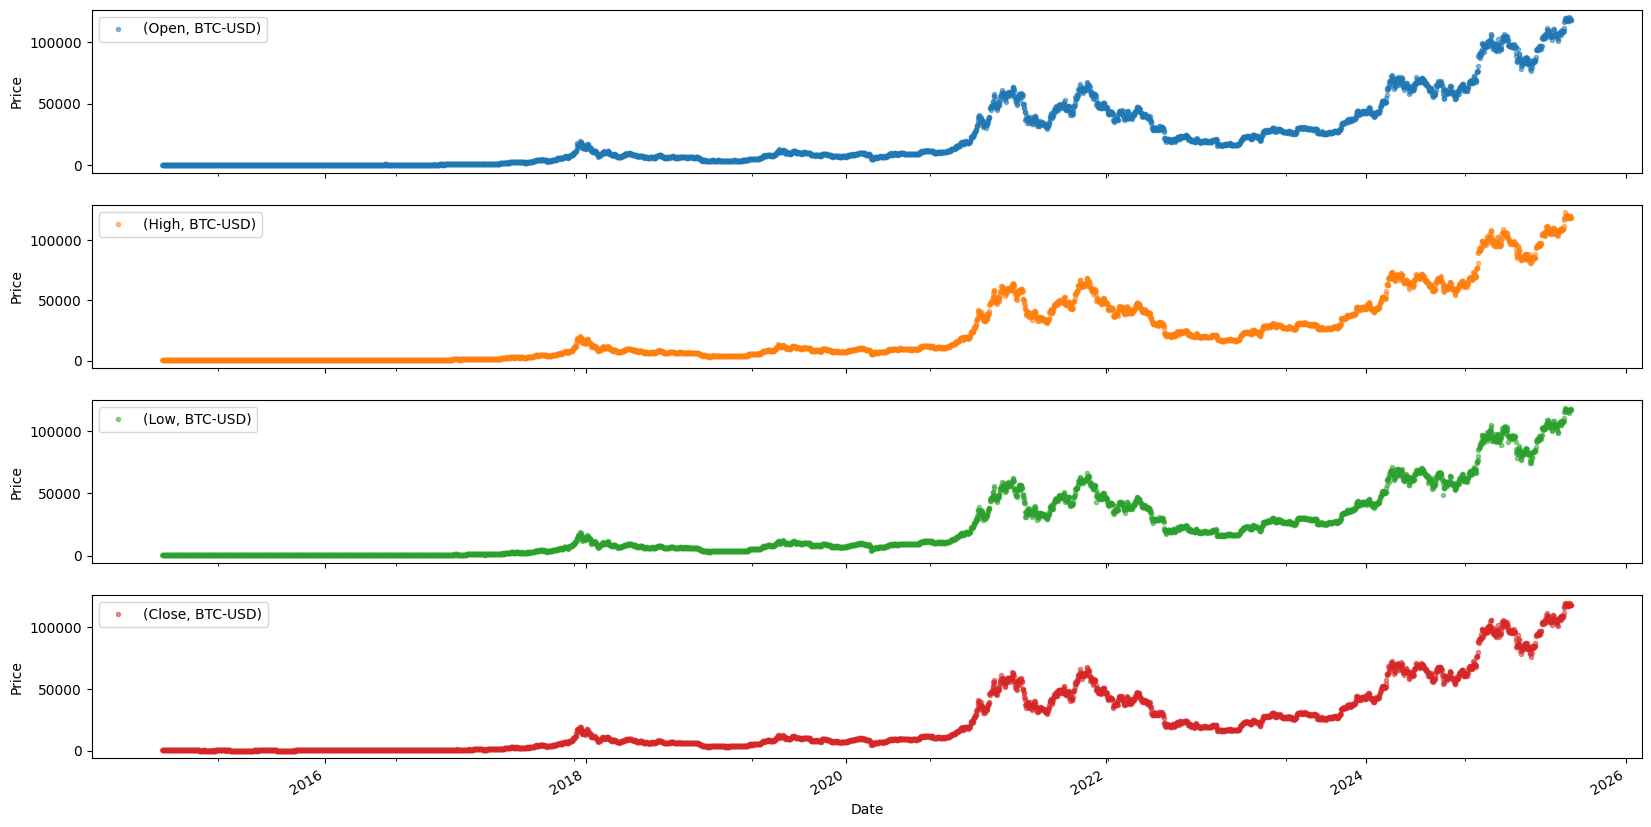

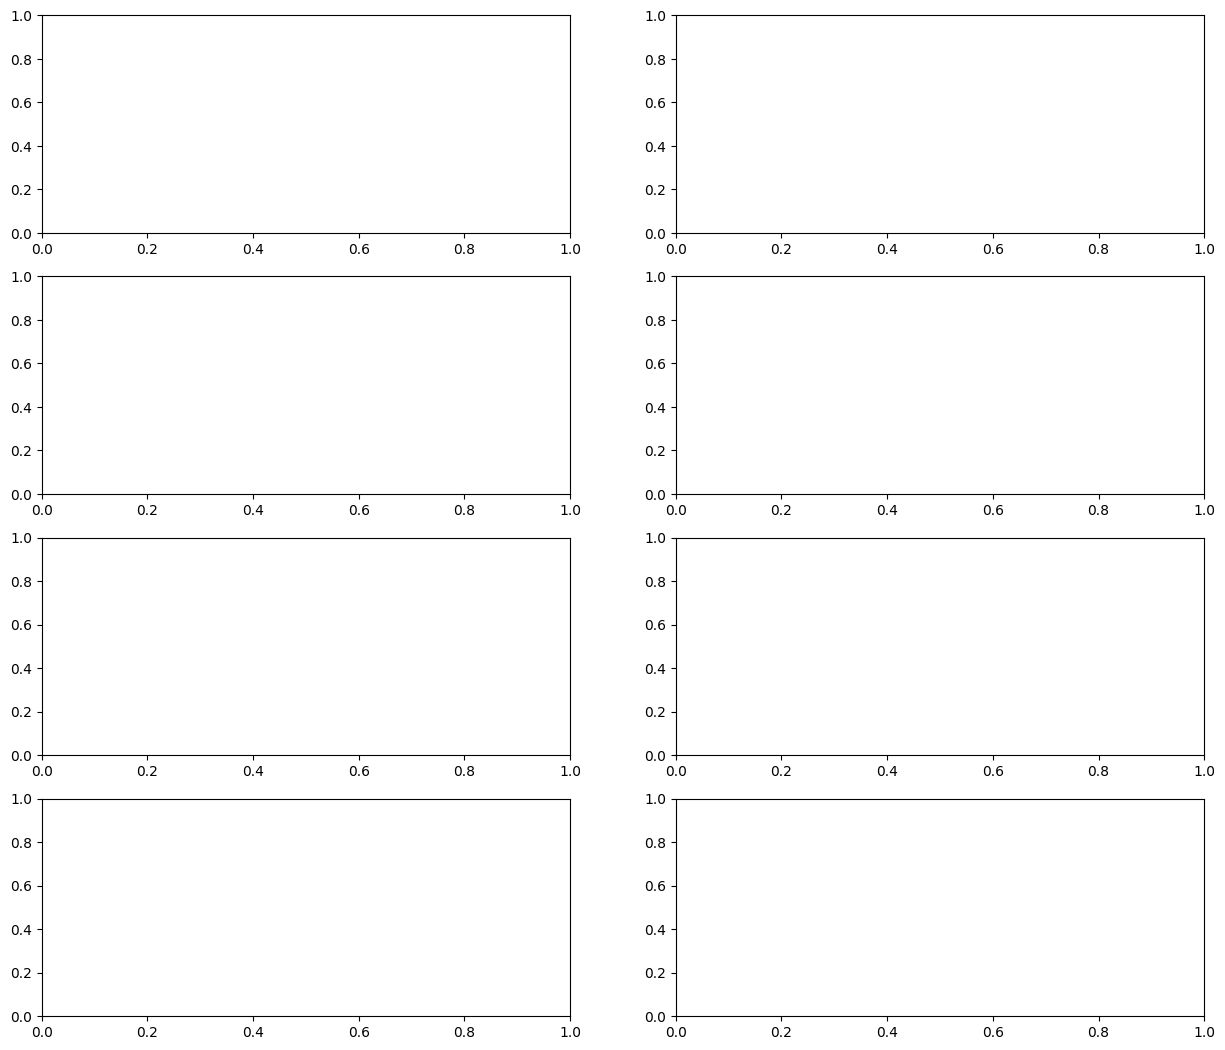

In [ ]:
# === COMBINED SCRIPT: Web Scraping, Preprocessing, Visualization, Modeling ===

import requests
import json
import time
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, BatchNormalization, GRU
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
import pickle

# === Web Scraping Placeholder (Coinbase API spot price fetch) ===
def fetch_coinbase_data():
    start_date = "2020-01-01"
    end_date = "2023-03-15"
    granularity = 86400
    url = f"https://api.coinbase.com/v2/prices/BTC-USD/spot?start={start_date}&end={end_date}&granularity={granularity}"
    prices = []
    while url:
        response = requests.get(url)
        data = json.loads(response.text)
        prices += data.get("data", {}).get("prices", [])
        url = data.get("pagination", {}).get("next_url", None)
        time.sleep(1)
    return prices

# === Data Loader ===
def load_data():
    data = yf.download("BTC-USD", start="2014-10-01", interval='1d')
    data.sort_index(inplace=True)
    data = data.loc[~data.index.duplicated(keep='first')]
    data.dropna(inplace=True)
    return data

# === Technical Indicator (RSI with fallback if no TA-Lib) ===
def technical_indicator():
    data = load_data()
    try:
        import talib
        data['RSI_14'] = talib.RSI(data['Close'], timeperiod=14)
    except:
        delta = data['Close'].diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
        RS = gain / loss
        data['RSI_14'] = 100 - (100 / (1 + RS))
    data['RSI_14'].fillna(50, inplace=True)
    return data

# === Preprocessing Utility ===
class MultiDimensionScaler():
    def __init__(self):
        self.scalers = []

    def fit_transform(self, X):
        total_dims = X.shape[2]
        for i in range(total_dims):
            scaler = MinMaxScaler()
            X[:, :, i] = scaler.fit_transform(X[:, :, i])
            self.scalers.append(scaler)
        return X

    def transform(self, X):
        for i in range(X.shape[2]):
            X[:, :, i] = self.scalers[i].transform(X[:, :, i])
        return X

# === Feature & Target Creator ===
def CreateFeatures_and_Targets(data, feature_length):
    X, Y = [], []
    for i in range(len(data) - feature_length):
        X.append(data.iloc[i:i + feature_length].values)
        Y.append(data['Close'].values[i + feature_length])
    return np.array(X), np.array(Y)

# === Save/Load Object ===
def save_object(obj, name):
    with open(f"{name}.pck", "wb") as f:
        pickle.dump(obj, f)

def load_object(name):
    with open(f"{name}.pck", "rb") as f:
        return pickle.load(f)

# === EDA (Exploratory Data Analysis) ===
def data_desc():
    data = load_data()
    print(data.describe())
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines'))
    fig.update_layout(title='BTC-USD Close Price', xaxis_title='Date', yaxis_title='Close')
    fig.show()

    cols_plot = ['Open', 'High', 'Low', 'Close']
    axes = data[cols_plot].plot(marker='.', alpha=0.5, linestyle='None', figsize=(20, 11), subplots=True)
    for ax in axes:
        ax.set_ylabel('Price')

# === Data Distribution ===
def data_distribution():
    data = load_data()
    fig, ax = plt.subplots(4, 2, figsize=(15, 13))
    sns.boxplot(x=data['Close'], ax=ax[0, 0])
    sns.histplot(data['Close'], kde=True, ax=ax[0, 1])
    sns.boxplot(x=data['Open'], ax=ax[1, 0])
    sns.histplot(data['Open'], kde=True, ax=ax[1, 1])
    sns.boxplot(x=data['High'], ax=ax[2, 0])
    sns.histplot(data['High'], kde=True, ax=ax[2, 1])
    sns.boxplot(x=data['Low'], ax=ax[3, 0])
    sns.histplot(data['Low'], kde=True, ax=ax[3, 1])
    plt.tight_layout()
    plt.show()

# === Correlation Matrix ===
def cor_matrix():
    data = load_data()
    plt.figure(figsize=(10, 6))
    sns.heatmap(data.corr(), cmap='Blues', annot=True)
    plt.title('Correlation Matrix')
    plt.show()

# === Main Execution ===
if __name__ == '__main__':
    data = technical_indicator()
    test_length = data[(data.index >= '2022-03-01')].shape[0]

    # Preprocess & Split
    X, Y = CreateFeatures_and_Targets(data[['Close', 'RSI_14']], 32)
    Xtrain, Xtest, Ytrain, Ytest = X[:-test_length], X[-test_length:], Y[:-test_length], Y[-test_length:]

    # Scaling
    Feature_Scaler = MultiDimensionScaler()
    Xtrain = Feature_Scaler.fit_transform(Xtrain)
    Xtest = Feature_Scaler.transform(Xtest)

    Target_Scaler = MinMaxScaler()
    Ytrain = Target_Scaler.fit_transform(Ytrain.reshape(-1, 1))
    Ytest = Target_Scaler.transform(Ytest.reshape(-1, 1))

    # Save Scalers
    save_object(Feature_Scaler, "Feature_Scaler")
    save_object(Target_Scaler, "Target_Scaler")

    # EDA
    data_desc()
    data_distribution()
    cor_matrix()

    print("Data preprocessing and analysis complete.")


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Price           Close           High            Low           Open  \
Ticker        BTC-USD        BTC-USD        BTC-USD        BTC-USD   
count     3956.000000    3956.000000    3956.000000    3956.000000   
mean     23878.931602   24355.783143   23324.311881   23850.222570   
std      28045.541051   28538.760605   27466.430851   28008.817536   
min        178.102997     211.731003     171.509995     176.897003   
25%       2486.622559    2557.549988    2375.547546    2489.062561   
50%      10180.006836   10386.951172    9864.953125   10176.371582   
75%      38122.640625   39312.143555   37110.909180   38104.682617   
max     119995.414062  123091.609375  118959.195312  119997.445312   

Price         Volume  
Ticker       BTC-USD  
count   3.956000e+03  
mean    2.017284e+10  
std     2.146927e+10  
min     5.914570e+06  
25%     1.072115e+09  
50%     1.633667e+10  
75%     3.153834e+10  
max     3.509679e+11  


[*********************100%***********************]  1 of 1 completed


ValueError: If using all scalar values, you must pass an index

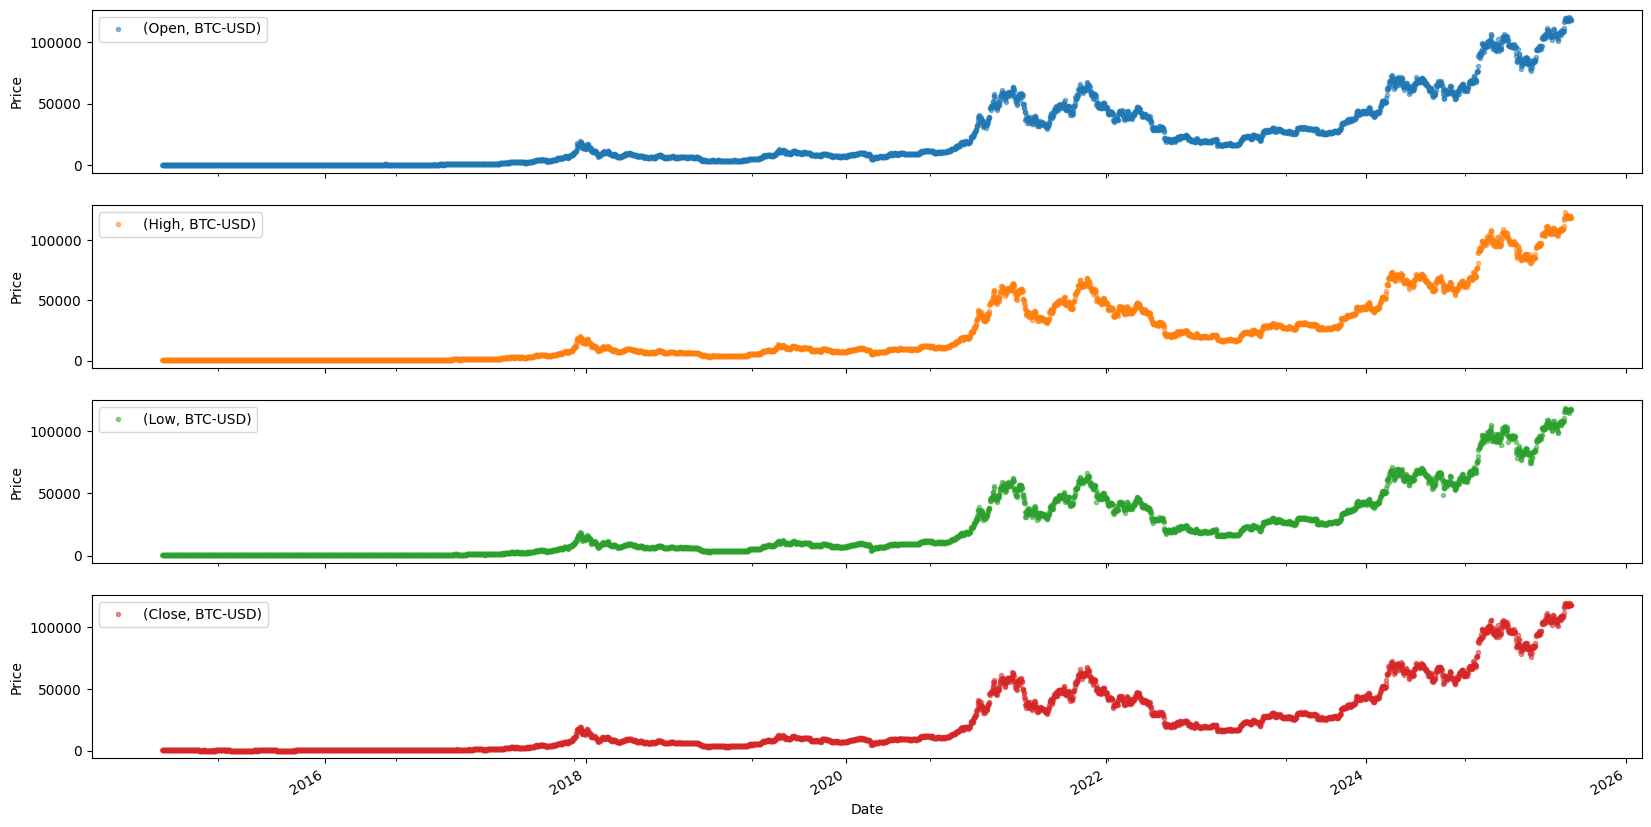

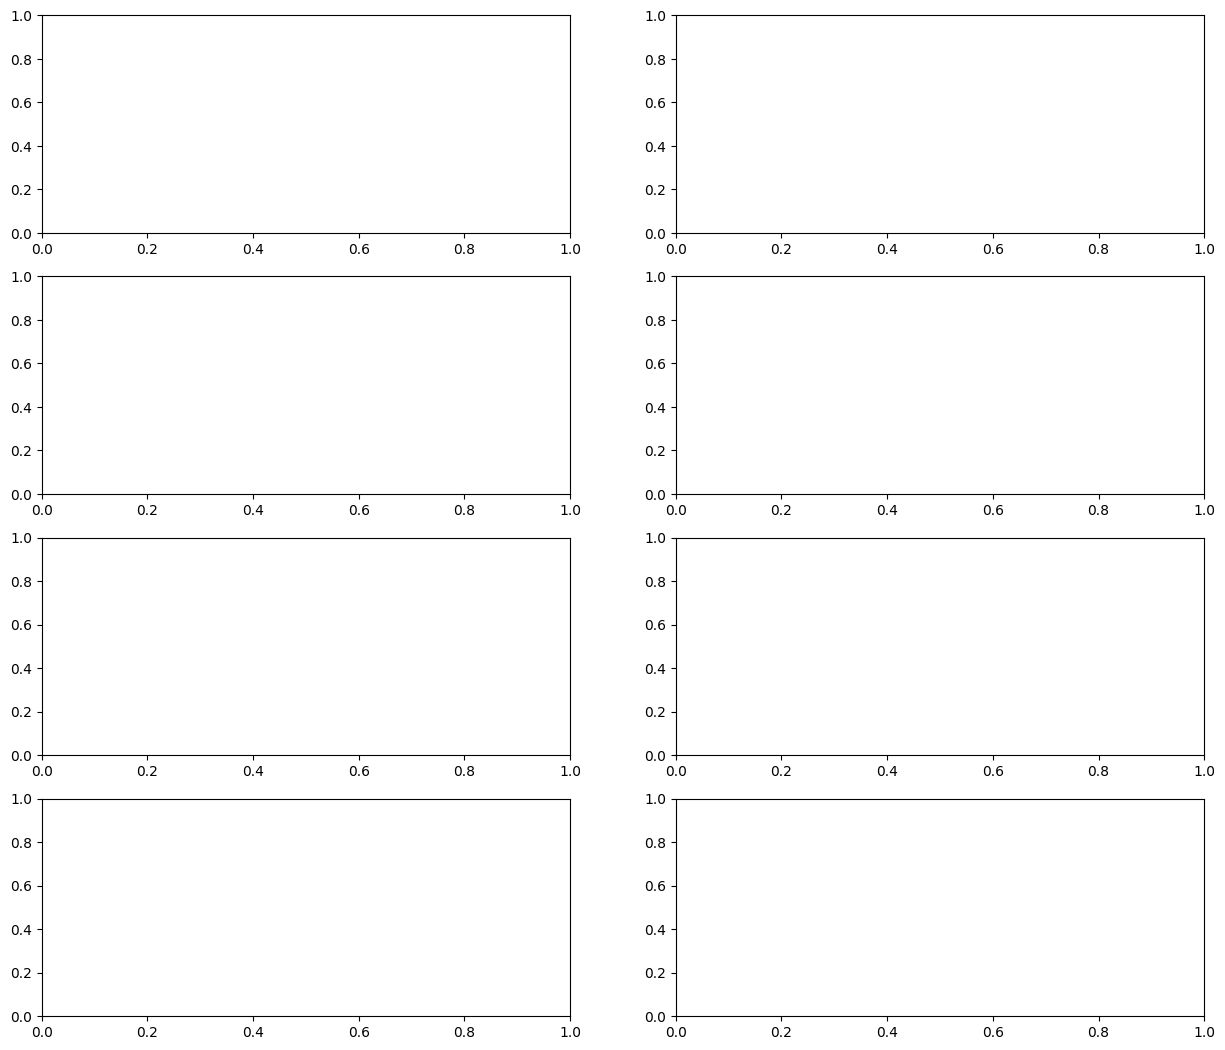

In [ ]:
# === COMBINED SCRIPT: Web Scraping, Preprocessing, Visualization, Modeling ===

import requests
import json
import time
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, BatchNormalization, GRU
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
import pickle

# === Web Scraping Placeholder (Coinbase API spot price fetch) ===
def fetch_coinbase_data():
    start_date = "2020-01-01"
    end_date = "2023-03-15"
    granularity = 86400
    url = f"https://api.coinbase.com/v2/prices/BTC-USD/spot?start={start_date}&end={end_date}&granularity={granularity}"
    prices = []
    while url:
        response = requests.get(url)
        data = json.loads(response.text)
        prices += data.get("data", {}).get("prices", [])
        url = data.get("pagination", {}).get("next_url", None)
        time.sleep(1)
    return prices

# === Data Loader ===
def load_data():
    data = yf.download("BTC-USD", start="2014-10-01", interval='1d')
    data.sort_index(inplace=True)
    data = data.loc[~data.index.duplicated(keep='first')]
    data.dropna(inplace=True)
    return data

# === Technical Indicator (RSI with fallback if no TA-Lib) ===
def technical_indicator():
    data = load_data()
    try:
        import talib
        data['RSI_14'] = talib.RSI(data['Close'], timeperiod=14)
    except:
        delta = data['Close'].diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
        RS = gain / loss
        data['RSI_14'] = 100 - (100 / (1 + RS))
    data['RSI_14'].fillna(50, inplace=True)
    return data

# === Preprocessing Utility ===
class MultiDimensionScaler():
    def __init__(self):
        self.scalers = []

    def fit_transform(self, X):
        total_dims = X.shape[2]
        for i in range(total_dims):
            scaler = MinMaxScaler()
            X[:, :, i] = scaler.fit_transform(X[:, :, i])
            self.scalers.append(scaler)
        return X

    def transform(self, X):
        for i in range(X.shape[2]):
            X[:, :, i] = self.scalers[i].transform(X[:, :, i])
        return X

# === Feature & Target Creator ===
def CreateFeatures_and_Targets(data, feature_length):
    X, Y = [], []
    for i in range(len(data) - feature_length):
        X.append(data.iloc[i:i + feature_length].values)
        Y.append(data['Close'].values[i + feature_length])
    return np.array(X), np.array(Y)

# === Save/Load Object ===
def save_object(obj, name):
    with open(f"{name}.pck", "wb") as f:
        pickle.dump(obj, f)

def load_object(name):
    with open(f"{name}.pck", "rb") as f:
        return pickle.load(f)

# === EDA (Exploratory Data Analysis) ===
def data_desc():
    data = load_data()
    print(data.describe())
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines'))
    fig.update_layout(title='BTC-USD Close Price', xaxis_title='Date', yaxis_title='Close')
    fig.show()

    cols_plot = ['Open', 'High', 'Low', 'Close']
    axes = data[cols_plot].plot(marker='.', alpha=0.5, linestyle='None', figsize=(20, 11), subplots=True)
    for ax in axes:
        ax.set_ylabel('Price')

# === Data Distribution ===
def data_distribution():
    data = load_data()

    for col in ['Close', 'Open', 'High', 'Low']:
        if col not in data.columns:
            raise ValueError(f"Kolom '{col}' tidak ditemukan dalam data.")

    fig, ax = plt.subplots(4, 2, figsize=(15, 13))
    sns.boxplot(x=data['Close'].dropna(), ax=ax[0, 0])
    sns.histplot(data['Close'].dropna(), kde=True, ax=ax[0, 1])
    sns.boxplot(x=data['Open'].dropna(), ax=ax[1, 0])
    sns.histplot(data['Open'].dropna(), kde=True, ax=ax[1, 1])
    sns.boxplot(x=data['High'].dropna(), ax=ax[2, 0])
    sns.histplot(data['High'].dropna(), kde=True, ax=ax[2, 1])
    sns.boxplot(x=data['Low'].dropna(), ax=ax[3, 0])
    sns.histplot(data['Low'].dropna(), kde=True, ax=ax[3, 1])
    fig.suptitle("Distribusi Harga Bitcoin", fontsize=16)
    plt.tight_layout()
    plt.show()

# === Correlation Matrix ===
def cor_matrix():
    data = load_data()
    plt.figure(figsize=(10, 6))
    sns.heatmap(data.corr(), cmap='Blues', annot=True)
    plt.title('Correlation Matrix')
    plt.show()

# === Main Execution ===
if __name__ == '__main__':
    data = technical_indicator()
    test_length = data[(data.index >= '2022-03-01')].shape[0]

    # Preprocess & Split
    X, Y = CreateFeatures_and_Targets(data[['Close', 'RSI_14']], 32)
    Xtrain, Xtest, Ytrain, Ytest = X[:-test_length], X[-test_length:], Y[:-test_length], Y[-test_length:]

    # Scaling
    Feature_Scaler = MultiDimensionScaler()
    Xtrain = Feature_Scaler.fit_transform(Xtrain)
    Xtest = Feature_Scaler.transform(Xtest)

    Target_Scaler = MinMaxScaler()
    Ytrain = Target_Scaler.fit_transform(Ytrain.reshape(-1, 1))
    Ytest = Target_Scaler.transform(Ytest.reshape(-1, 1))

    # Save Scalers
    save_object(Feature_Scaler, "Feature_Scaler")
    save_object(Target_Scaler, "Target_Scaler")

    # EDA
    data_desc()
    data_distribution()
    cor_matrix()

    print("Data preprocessing and analysis complete.")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


===== DATA HEAD =====
Price            Close        High         Low        Open    Volume
Ticker         BTC-USD     BTC-USD     BTC-USD     BTC-USD   BTC-USD
Date                                                                
2014-10-01  383.614990  391.378998  380.779999  387.427002  26229400
2014-10-02  375.071991  385.497009  372.946014  383.988007  21777700
2014-10-03  359.511993  377.695007  357.859009  375.181000  30901200
2014-10-04  328.865997  364.487000  325.885986  359.891998  47236500
2014-10-05  320.510010  341.800995  289.295990  328.915985  83308096

===== DATA INFO =====
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3956 entries, 2014-10-01 to 2025-07-31
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Close, BTC-USD)   3956 non-null   float64
 1   (High, BTC-USD)    3956 non-null   float64
 2   (Low, BTC-USD)     3956 non-null   float64
 3   (Open, BTC-USD)    3956 non-null 

[*********************100%***********************]  1 of 1 completed


ValueError: If using all scalar values, you must pass an index

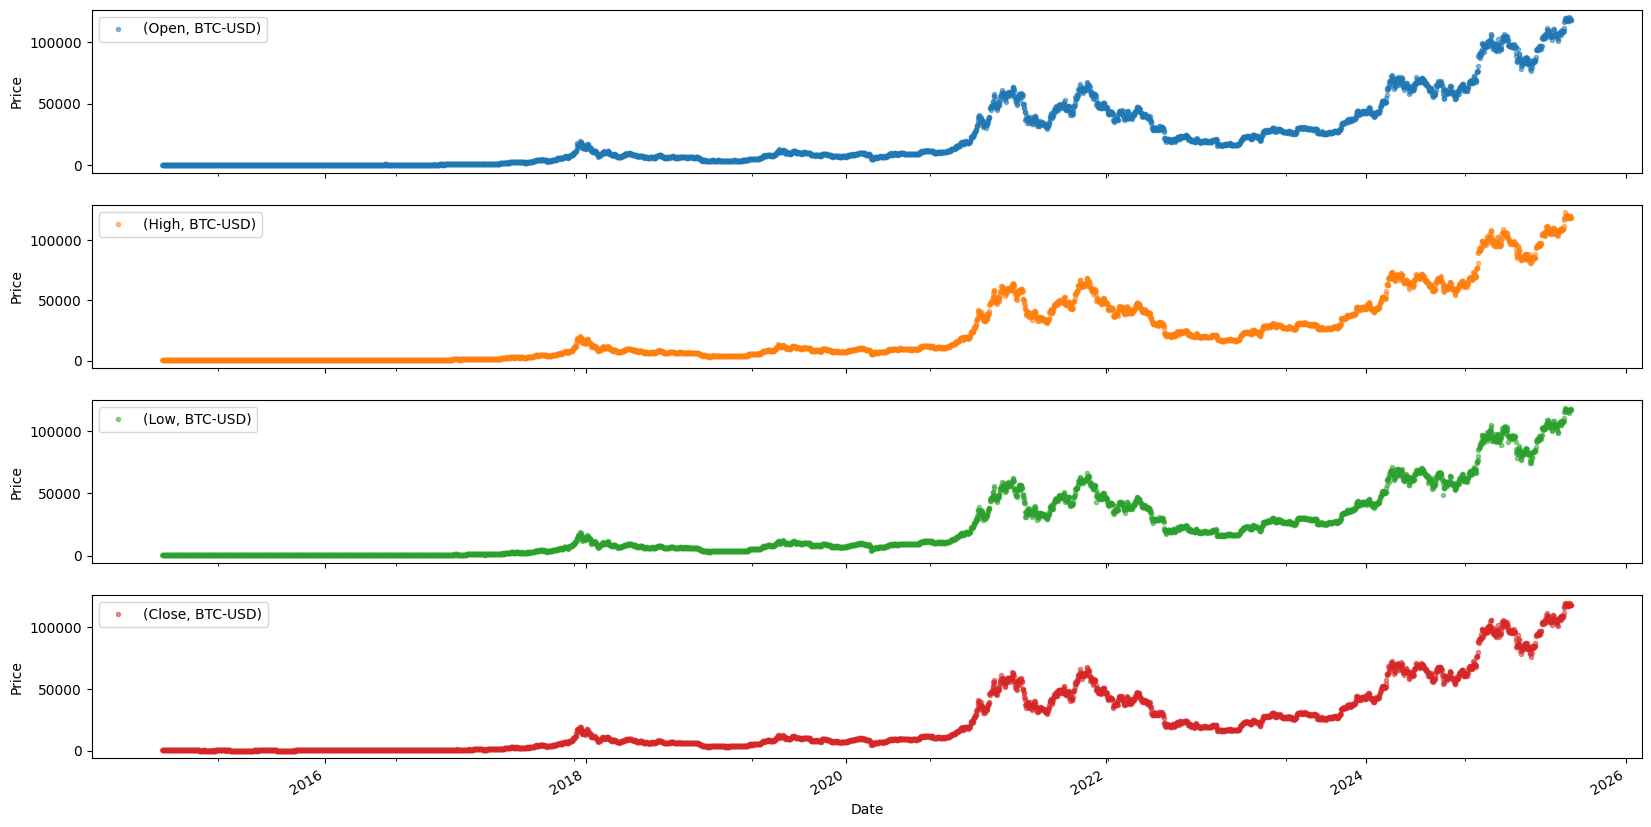

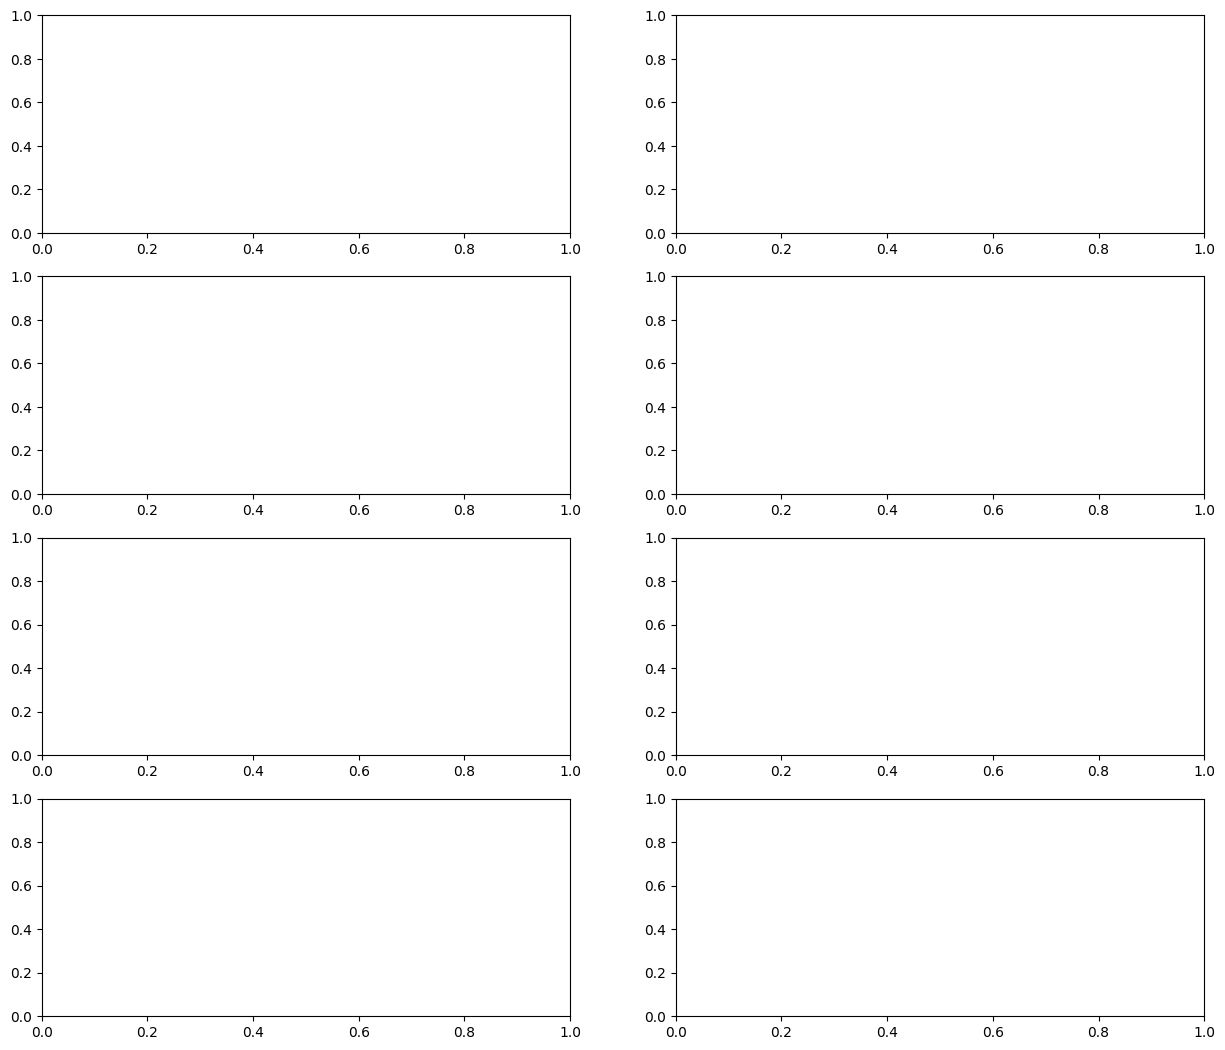

In [ ]:
# === COMBINED SCRIPT: Web Scraping, Preprocessing, Visualization, Modeling ===

import requests
import json
import time
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, BatchNormalization, GRU
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
import pickle

# === Web Scraping Placeholder (Coinbase API spot price fetch) ===
def fetch_coinbase_data():
    start_date = "2020-01-01"
    end_date = "2023-03-15"
    granularity = 86400
    url = f"https://api.coinbase.com/v2/prices/BTC-USD/spot?start={start_date}&end={end_date}&granularity={granularity}"
    prices = []
    while url:
        response = requests.get(url)
        data = json.loads(response.text)
        prices += data.get("data", {}).get("prices", [])
        url = data.get("pagination", {}).get("next_url", None)
        time.sleep(1)
    return prices

# === Data Loader ===
def load_data():
    data = yf.download("BTC-USD", start="2014-10-01", interval='1d')
    data.sort_index(inplace=True)
    data = data.loc[~data.index.duplicated(keep='first')]
    data.dropna(inplace=True)
    return data

# === Technical Indicator (RSI with fallback if no TA-Lib) ===
def technical_indicator():
    data = load_data()
    try:
        import talib
        data['RSI_14'] = talib.RSI(data['Close'], timeperiod=14)
    except:
        delta = data['Close'].diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
        RS = gain / loss
        data['RSI_14'] = 100 - (100 / (1 + RS))
    data['RSI_14'].fillna(50, inplace=True)
    return data

# === Preprocessing Utility ===
class MultiDimensionScaler():
    def __init__(self):
        self.scalers = []

    def fit_transform(self, X):
        total_dims = X.shape[2]
        for i in range(total_dims):
            scaler = MinMaxScaler()
            X[:, :, i] = scaler.fit_transform(X[:, :, i])
            self.scalers.append(scaler)
        return X

    def transform(self, X):
        for i in range(X.shape[2]):
            X[:, :, i] = self.scalers[i].transform(X[:, :, i])
        return X

# === Feature & Target Creator ===
def CreateFeatures_and_Targets(data, feature_length):
    X, Y = [], []
    for i in range(len(data) - feature_length):
        X.append(data.iloc[i:i + feature_length].values)
        Y.append(data['Close'].values[i + feature_length])
    return np.array(X), np.array(Y)

# === Save/Load Object ===
def save_object(obj, name):
    with open(f"{name}.pck", "wb") as f:
        pickle.dump(obj, f)

def load_object(name):
    with open(f"{name}.pck", "rb") as f:
        return pickle.load(f)

# === EDA (Exploratory Data Analysis) ===
def data_desc():
    data = load_data()
    print("\n===== DATA HEAD =====")
    print(data.head())
    print("\n===== DATA INFO =====")
    print(data.info())
    print("\n===== DATA DESCRIBE =====")
    print(data.describe())

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=data.index, y=data['Close'], mode='lines'))
    fig.update_layout(title='BTC-USD Close Price', xaxis_title='Date', yaxis_title='Close')
    fig.show()

    cols_plot = ['Open', 'High', 'Low', 'Close']
    axes = data[cols_plot].plot(marker='.', alpha=0.5, linestyle='None', figsize=(20, 11), subplots=True)
    for ax in axes:
        ax.set_ylabel('Price')

# === Data Distribution ===
def data_distribution():
    data = load_data()

    for col in ['Close', 'Open', 'High', 'Low']:
        if col not in data.columns:
            raise ValueError(f"Kolom '{col}' tidak ditemukan dalam data.")

    fig, ax = plt.subplots(4, 2, figsize=(15, 13))
    sns.boxplot(x=data['Close'].dropna(), ax=ax[0, 0])
    sns.histplot(data['Close'].dropna(), kde=True, ax=ax[0, 1])
    sns.boxplot(x=data['Open'].dropna(), ax=ax[1, 0])
    sns.histplot(data['Open'].dropna(), kde=True, ax=ax[1, 1])
    sns.boxplot(x=data['High'].dropna(), ax=ax[2, 0])
    sns.histplot(data['High'].dropna(), kde=True, ax=ax[2, 1])
    sns.boxplot(x=data['Low'].dropna(), ax=ax[3, 0])
    sns.histplot(data['Low'].dropna(), kde=True, ax=ax[3, 1])
    fig.suptitle("Distribusi Harga Bitcoin", fontsize=16)
    plt.tight_layout()
    plt.show()

# === Correlation Matrix ===
def cor_matrix():
    data = load_data()
    plt.figure(figsize=(10, 6))
    sns.heatmap(data.corr(), cmap='Blues', annot=True)
    plt.title('Correlation Matrix')
    plt.show()

# === Main Execution ===
if __name__ == '__main__':
    data = technical_indicator()
    test_length = data[(data.index >= '2022-03-01')].shape[0]

    # Preprocess & Split
    X, Y = CreateFeatures_and_Targets(data[['Close', 'RSI_14']], 32)
    Xtrain, Xtest, Ytrain, Ytest = X[:-test_length], X[-test_length:], Y[:-test_length], Y[-test_length:]

    # Scaling
    Feature_Scaler = MultiDimensionScaler()
    Xtrain = Feature_Scaler.fit_transform(Xtrain)
    Xtest = Feature_Scaler.transform(Xtest)

    Target_Scaler = MinMaxScaler()
    Ytrain = Target_Scaler.fit_transform(Ytrain.reshape(-1, 1))
    Ytest = Target_Scaler.transform(Ytest.reshape(-1, 1))

    # Save Scalers
    save_object(Feature_Scaler, "Feature_Scaler")
    save_object(Target_Scaler, "Target_Scaler")

    # EDA
    data_desc()
    data_distribution()
    cor_matrix()

    print("Data preprocessing and analysis complete.")


In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.python.keras.layers.legacy_rnn.rnn_cell_impl import BasicLSTMCell
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, BatchNormalization, GRU, Embedding
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
import math
import plotly.graph_objects as go
from sklearn.preprocessing import MinMaxScaler
import pickle
from tqdm.notebook import tnrange
import talib
from data.data import *
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import Conv1D, LSTM, Dense, Dropout, Bidirectional, TimeDistributed, Conv1D, \
    RepeatVector, Reshape, Conv2D
from tensorflow.keras.optimizers import Adam

def cnn_lstm():
    model_cnn_lstm = Sequential()
    model_cnn_lstm.add(Conv2D(128, (3, 3), input_shape=(None, Xtrain.shape[2], 1)))
    # mod_cnn_lstmel.add(MaxPool2D(pool_size=(2, 2))) by imposing kernel_size_y to #features
    model_cnn_lstm.add(Dropout(0.2))
    model_cnn_lstm.add(Reshape(target_shape=(30, 128)))
    model_cnn_lstm.add(LSTM(128, return_sequences=False))
    model_cnn_lstm.add(Dense(128, activation='relu'))
    model_cnn_lstm.add(Dense(1))
    model_cnn_lstm.compile(loss='mse', optimizer=optimizer, metrics=['mae'])


def model():
    save_best = ModelCheckpoint("GRU_best_weights.h5", monitor='val_loss', save_best_only=True, save_weights_only=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=5, min_lr=0.00001, verbose=1)
    CNN_LSTM_model = cnn_lstm()
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

    return CNN_LSTM_model, optimizer


if __name__ == '__main__':
    # X_train_series_sub = Xtrain.reshape((Xtrain.shape[0], 32, 3, 1))
    # X_valid_series_sub = Xtest.reshape((Xtest.shape[0], 32, 3, 1))
    model, optimizer = model()
    model.compile(loss='mse', optimizer=optimizer, metrics=['mae'])

ModuleNotFoundError: No module named 'talib'

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dropout, Reshape, LSTM, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Step 1: Unduh data saham
def load_stock_data(ticker='AAPL', start='2020-01-01', end='2024-01-01'):
    df = yf.download(ticker, start=start, end=end)
    df = df[['Close']]
    df.dropna(inplace=True)
    return df

# Step 2: Preprocessing
def preprocess_data(df, time_steps=30):
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(df)

    X, y = [], []
    for i in range(time_steps, len(scaled_data)):
        X.append(scaled_data[i-time_steps:i])
        y.append(scaled_data[i])

    X, y = np.array(X), np.array(y)
    X = X.reshape((X.shape[0], time_steps, 1, 1))  # (samples, timesteps, features, channel)
    return X, y, scaler

# Step 3: CNN-LSTM Model
def cnn_lstm_model(input_shape):
    model = Sequential()
    model.add(Conv2D(128, (3, 1), input_shape=input_shape, activation='relu'))
    model.add(Dropout(0.2))
    model.add(Reshape((input_shape[0], 128)))
    model.add(LSTM(128, return_sequences=False))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1))
    return model

# Step 4: Train Model
def train_model(X_train, y_train, X_val, y_val, epochs=50, batch_size=32):
    input_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3])
    model = cnn_lstm_model(input_shape)
    optimizer = Adam(learning_rate=0.001)
    model.compile(loss='mse', optimizer=optimizer, metrics=['mae'])

    checkpoint = ModelCheckpoint("cnn_lstm_best_weights.h5", monitor='val_loss', save_best_only=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=5, min_lr=1e-5, verbose=1)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[checkpoint, reduce_lr],
        verbose=1
    )
    return model, history

# Step 5: Evaluasi
def evaluate_model(model, X_test, y_test, scaler):
    predictions = model.predict(X_test)
    predictions = scaler.inverse_transform(predictions)
    y_test_inv = scaler.inverse_transform(y_test)

    mse = mean_squared_error(y_test_inv, predictions)
    mae = median_absolute_error(y_test_inv, predictions)
    mape = mean_absolute_percentage_error(y_test_inv, predictions)
    r2 = r2_score(y_test_inv, predictions)

    print(f"MSE: {mse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"MAPE: {mape:.4f}")
    print(f"R² Score: {r2:.4f}")

    plt.plot(y_test_inv, label='Actual')
    plt.plot(predictions, label='Predicted')
    plt.legend()
    plt.title('Actual vs Predicted')
    plt.show()

# === Main Execution ===
if __name__ == '__main__':
    df = load_stock_data()
    X, y, scaler = preprocess_data(df)

    # Split
    split = int(len(X) * 0.8)
    X_train, y_train = X[:split], y[:split]
    X_val, y_val = X[split:], y[split:]

    model, history = train_model(X_train, y_train, X_val, y_val)
    evaluate_model(model, X_val, y_val, scaler)


[*********************100%***********************]  1 of 1 completed


ValueError: The total size of the tensor must be unchanged. Received: input_shape=(28, 1, 128), target_shape=(30, 128)

[*********************100%***********************]  1 of 1 completed

Epoch 1/50


34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 0.0542 - mae: 0.1667

34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 0.0532 - mae: 0.1645 - val_loss: 0.0023 - val_mae: 0.0398 - learning_rate: 0.0010
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 9.6018e-04 - mae: 0.0241 - val_loss: 0.0025 - val_mae: 0.0419 - learning_rate: 0.0010
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 8.1050e-04 - mae: 0.0228 - val_loss: 0.0033 - val_mae: 0.0493 - learning_rate: 0.0010
Epoch 4/50
33/34 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 7.4956e-04 - mae: 0.0216

34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 7.4811e-04 - mae: 0.0216 - val_loss: 0.0015 - val_mae: 0.0295 - learning_rate: 0.0010
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 8.3382e-04 - mae: 0.0227 - val_loss: 0.0018 - val_mae: 0.0343 - learning_rate: 0.0010
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 6.9709e-04 - mae: 0.0210

34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 6.9685e-04 - mae: 0.0210 - val_loss: 0.0014 - val_mae: 0.0288 - learning_rate: 0.0010
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 7.1718e-04 - mae: 0.0209 - val_loss: 0.0024 - val_mae: 0.0411 - learning_rate: 0.0010
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 6.8500e-04 - mae: 0.0205 - val_loss: 0.0045 - val_mae: 0.0605 - learning_rate: 0.0010
Epoch 9/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 6.8863e-04 - mae: 0.0206
Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 6.8871e-04 - mae: 0.0206 - val_loss: 0.0022 - val_mae: 0.0388 - learning_rate: 0.0010
Epoch 10/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 6.7592e-04 - mae: 0.0204 - val_loss: 0.0028 - val_mae: 0.0446 - learning_rate: 2.5000e-04
Epoch 11/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 6.0554e-04 - mae: 0.0196 - val_loss: 0.0028 - val_mae: 0.0448 - learning

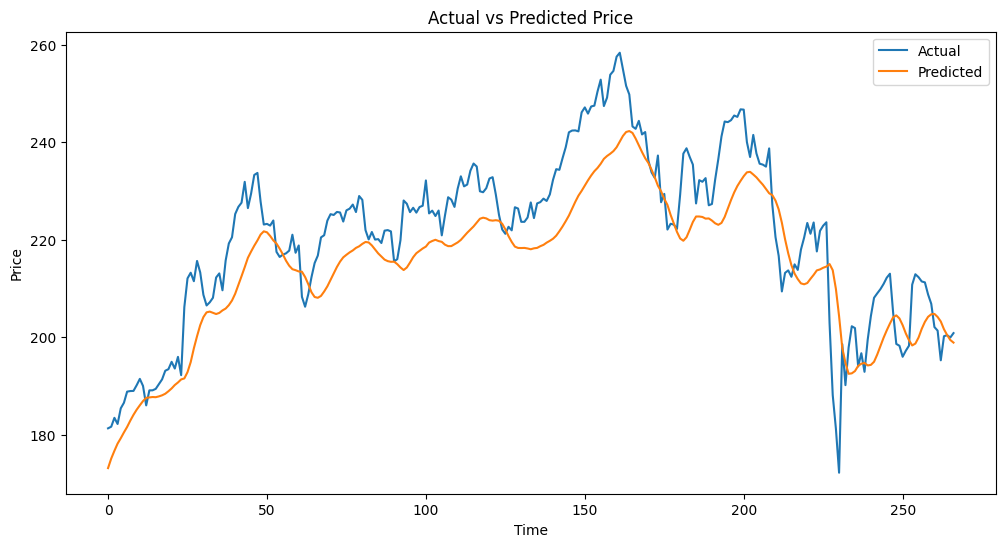

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, median_absolute_error, mean_absolute_percentage_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dropout, Reshape, LSTM, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# ==== STEP 1: Load Data ====
def load_stock_data(ticker='AAPL', start='2020-01-01', end='2025-06-01'):
    df = yf.download(ticker, start=start, end=end)
    df = df[['Close']].dropna()
    return df

# ==== STEP 2: Preprocess ====
def preprocess_data(df, time_steps=28):
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(df)

    X, y = [], []
    for i in range(time_steps, len(scaled)):
        X.append(scaled[i-time_steps:i])
        y.append(scaled[i])
    X = np.array(X)
    y = np.array(y)

    # Tambahkan dimensi channel = 1 → (samples, timesteps, features, channel)
    X = X.reshape((X.shape[0], X.shape[1], 1, 1))
    return X, y, scaler

# ==== STEP 3: Model CNN-LSTM ====
def cnn_lstm_model(input_shape):
    time_steps = input_shape[0]

    model = Sequential()
    model.add(Conv2D(128, (3, 1), activation='relu', input_shape=input_shape))
    model.add(Dropout(0.2))
    model.add(Reshape(target_shape=(time_steps - 2, 128)))  # -2 karena kernel_size=(3,1) mengurangi 2 step
    model.add(LSTM(128, return_sequences=False))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1))
    return model

# ==== STEP 4: Train Model ====
def train_model(X_train, y_train, X_val, y_val, epochs=50, batch_size=32):
    input_shape = X_train.shape[1:]  # (time_steps, 1, 1)
    model = cnn_lstm_model(input_shape)
    optimizer = Adam(learning_rate=0.001)
    model.compile(loss='mse', optimizer=optimizer, metrics=['mae'])

    checkpoint = ModelCheckpoint("cnn_lstm_best_weights.h5", monitor='val_loss', save_best_only=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=5, min_lr=1e-5, verbose=1)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[checkpoint, reduce_lr],
        verbose=1
    )
    return model, history

# ==== STEP 5: Evaluation ====
def evaluate_model(model, X_test, y_test, scaler):
    predictions = model.predict(X_test)
    predictions = scaler.inverse_transform(predictions)
    y_test_inv = scaler.inverse_transform(y_test)

    mse = mean_squared_error(y_test_inv, predictions)
    mae = median_absolute_error(y_test_inv, predictions)
    mape = mean_absolute_percentage_error(y_test_inv, predictions)
    r2 = r2_score(y_test_inv, predictions)

    print(f"MSE: {mse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"MAPE: {mape:.4f}")
    print(f"R² Score: {r2:.4f}")

    plt.figure(figsize=(12, 6))
    plt.plot(y_test_inv, label='Actual')
    plt.plot(predictions, label='Predicted')
    plt.legend()
    plt.title('Actual vs Predicted Price')
    plt.xlabel('Time')
    plt.ylabel('Price')
    plt.show()

# ==== MAIN ====
if __name__ == '__main__':
    # Load data
    df = load_stock_data(ticker='AAPL')
    time_steps = 28
    X, y, scaler = preprocess_data(df, time_steps=time_steps)

    # Split train/val
    split = int(len(X) * 0.8)
    X_train, y_train = X[:split], y[:split]
    X_val, y_val = X[split:], y[split:]

    # Train
    model, history = train_model(X_train, y_train, X_val, y_val)

    # Evaluate
    evaluate_model(model, X_val, y_val, scaler)



[*********************100%***********************]  1 of 1 completed

Epoch 1/50


68/69 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0159 - mae: 0.0668

69/69 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - loss: 0.0156 - mae: 0.0658 - val_loss: 4.4927e-04 - val_mae: 0.0169 - learning_rate: 0.0010
Epoch 2/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - loss: 2.8641e-04 - mae: 0.0107 - val_loss: 6.6286e-04 - val_mae: 0.0207 - learning_rate: 0.0010
Epoch 3/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - loss: 2.4061e-04 - mae: 0.0097 - val_loss: 9.4962e-04 - val_mae: 0.0250 - learning_rate: 0.0010
Epoch 4/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - loss: 2.1886e-04 - mae: 0.0093 - val_loss: 0.0015 - val_mae: 0.0324 - learning_rate: 0.0010
Epoch 5/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - loss: 2.3260e-04 - mae: 0.0095 - val_loss: 0.0020 - val_mae: 0.0380 - learning_rate: 0.0010
Epoch 6/50
68/69 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.2395e-04 - mae: 0.0097
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 2.2434e-04 - mae: 0.0097 - val_loss: 0.0036 - val_mae: 0.0535 - learni

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


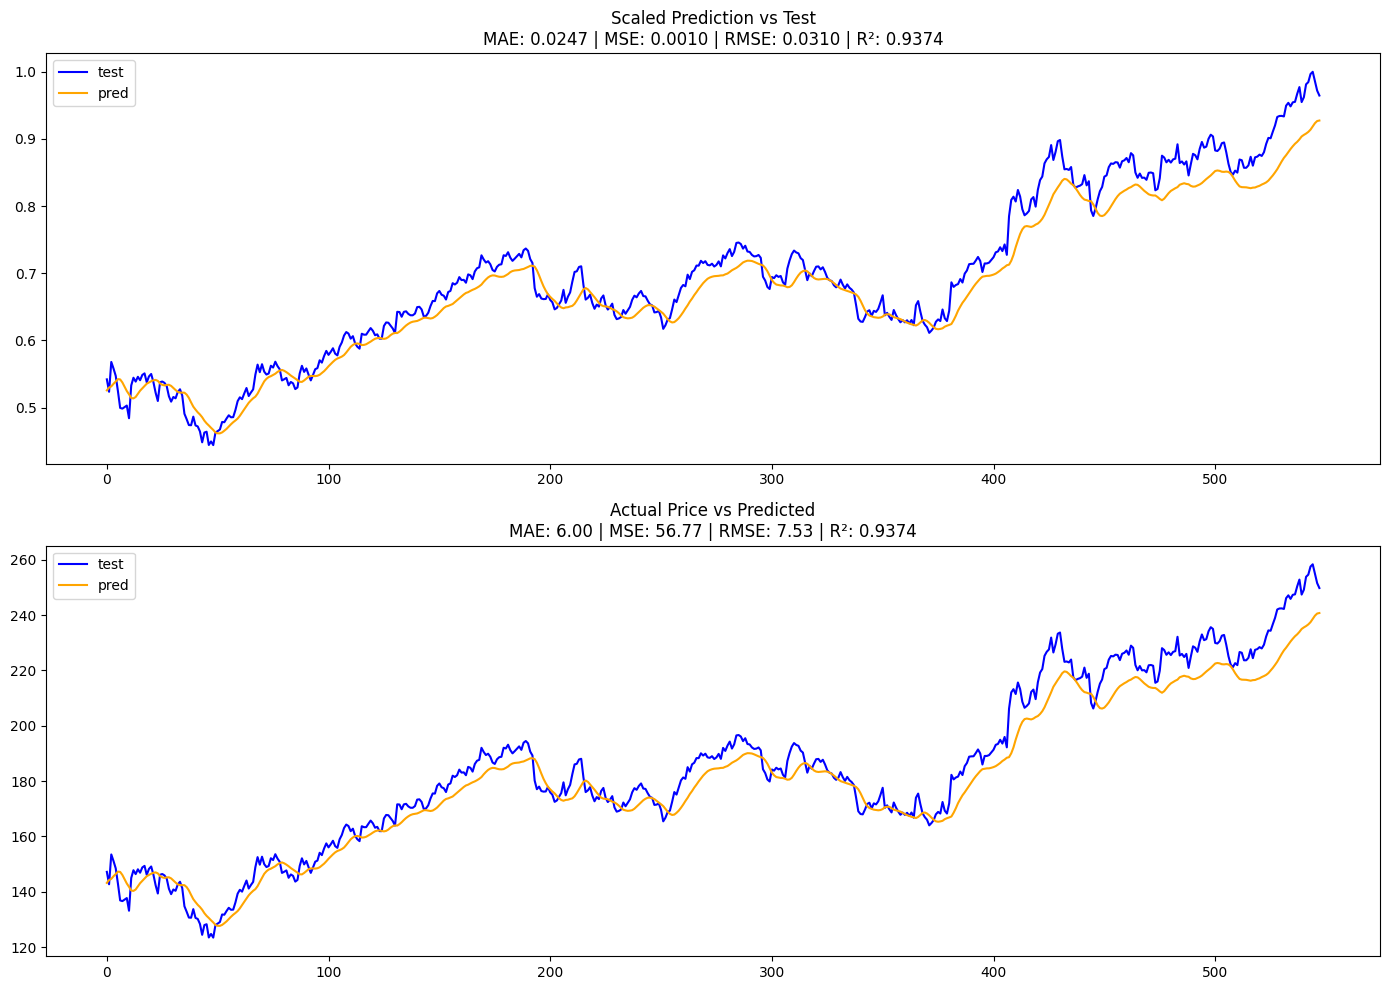

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dropout, Reshape, LSTM, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import math

# Load data saham
def load_data(ticker='AAPL', start='2014-01-01', end='2025-01-01'):
    df = yf.download(ticker, start=start, end=end)
    return df[['Close']].dropna()

# Preprocessing data
def preprocess(df, time_steps=30):
    scaler = MinMaxScaler()
    data_scaled = scaler.fit_transform(df)

    X, y = [], []
    for i in range(time_steps, len(data_scaled)):
        X.append(data_scaled[i-time_steps:i])
        y.append(data_scaled[i])
    X = np.array(X)
    y = np.array(y)
    X = X.reshape((X.shape[0], X.shape[1], 1, 1))  # (samples, timesteps, 1, 1)
    return X, y, scaler

# CNN-LSTM model
def build_model(input_shape):
    time_steps = input_shape[0] - 2  # karena Conv2D dengan kernel_size=(3,1)
    model = Sequential()
    model.add(Conv2D(128, (3, 1), activation='relu', input_shape=input_shape))
    model.add(Dropout(0.2))
    model.add(Reshape((time_steps, 128)))
    model.add(LSTM(128))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1))
    return model

# Train model
def train_model(X_train, y_train, X_val, y_val):
    input_shape = X_train.shape[1:]
    model = build_model(input_shape)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

    checkpoint = ModelCheckpoint("cnn_lstm_best.h5", save_best_only=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=5, min_lr=1e-5, verbose=1)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        callbacks=[checkpoint, reduce_lr],
        verbose=1
    )
    return model

# Evaluasi dan plotting
def evaluate_plot(model, X_test, y_test, scaler):
    pred_scaled = model.predict(X_test)
    y_scaled = y_test

    # Evaluasi dalam skala normalisasi
    mae_s = mean_absolute_error(y_scaled, pred_scaled)
    mse_s = mean_squared_error(y_scaled, pred_scaled)
    rmse_s = math.sqrt(mse_s)
    r2_s = r2_score(y_scaled, pred_scaled)

    # Invers transformasi
    pred_real = scaler.inverse_transform(pred_scaled)
    y_real = scaler.inverse_transform(y_scaled)

    # Evaluasi dalam skala harga asli
    mae_r = mean_absolute_error(y_real, pred_real)
    mse_r = mean_squared_error(y_real, pred_real)
    rmse_r = math.sqrt(mse_r)
    r2_r = r2_score(y_real, pred_real)

    # Plot 1: Scaled
    plt.figure(figsize=(14, 10))
    plt.subplot(2, 1, 1)
    plt.plot(y_scaled, label='test', color='blue')
    plt.plot(pred_scaled, label='pred', color='orange')
    plt.title(f"Scaled Prediction vs Test\nMAE: {mae_s:.4f} | MSE: {mse_s:.4f} | RMSE: {rmse_s:.4f} | R²: {r2_s:.4f}")
    plt.legend()

    # Plot 2: Actual Price
    plt.subplot(2, 1, 2)
    plt.plot(y_real, label='test', color='blue')
    plt.plot(pred_real, label='pred', color='orange')
    plt.title(f"Actual Price vs Predicted\nMAE: {mae_r:.2f} | MSE: {mse_r:.2f} | RMSE: {rmse_r:.2f} | R²: {r2_r:.4f}")
    plt.legend()
    plt.tight_layout()
    plt.show()

# MAIN
if __name__ == '__main__':
    ticker = 'AAPL'
    df = load_data(ticker)
    time_steps = 30
    X, y, scaler = preprocess(df, time_steps)

    # Split data
    split = int(len(X) * 0.8)
    X_train, y_train = X[:split], y[:split]
    X_val, y_val = X[split:], y[split:]

    # Train and evaluate
    model = train_model(X_train, y_train, X_val, y_val)
    evaluate_plot(model, X_val, y_val, scaler)


[*********************100%***********************]  1 of 1 completed

Epoch 1/150


69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0159 - mae: 0.0621

69/69 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - loss: 0.0158 - mae: 0.0616 - val_loss: 5.8196e-04 - val_mae: 0.0189 - learning_rate: 0.0010
Epoch 2/150
68/69 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 2.1180e-04 - mae: 0.0095

69/69 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - loss: 2.1165e-04 - mae: 0.0095 - val_loss: 5.4728e-04 - val_mae: 0.0186 - learning_rate: 0.0010
Epoch 3/150
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 2.1117e-04 - mae: 0.0090 - val_loss: 0.0018 - val_mae: 0.0361 - learning_rate: 0.0010
Epoch 4/150
69/69 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 2.4706e-04 - mae: 0.0098 - val_loss: 9.3446e-04 - val_mae: 0.0243 - learning_rate: 0.0010
Epoch 5/150
69/69 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - loss: 2.0225e-04 - mae: 0.0088 - val_loss: 0.0013 - val_mae: 0.0299 - learning_rate: 0.0010
Epoch 6/150
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 2.0447e-04 - mae: 0.0091
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 2.0452e-04 - mae: 0.0091 - val_loss: 0.0010 - val_mae: 0.0261 - learning_rate: 0.0010
Epoch 7/150
69/69 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 1.8916e-04 - mae: 0.0087 - val_loss: 0.0012 - val_mae: 0.0282 - l

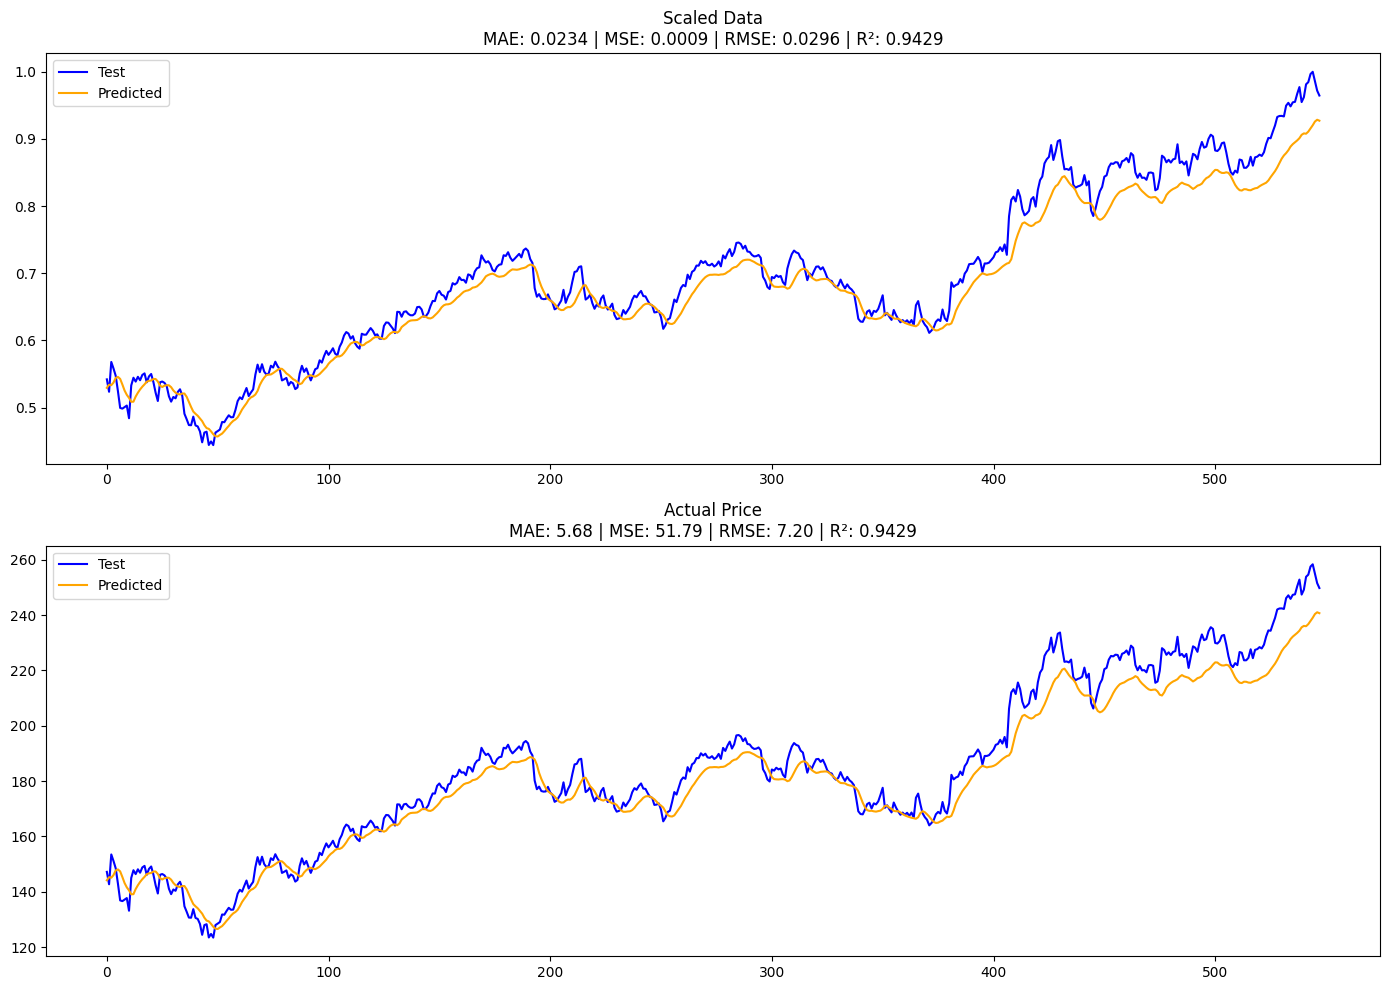

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dropout, Reshape, LSTM, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import math

# ===== Load Data =====
def load_stock_data(ticker='AAPL', start='2014-01-01', end='2025-01-01'):
    df = yf.download(ticker, start=start, end=end)
    return df[['Close']].dropna()

# ===== Preprocess =====
def preprocess(df, time_steps=30):
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(df)

    X, y = [], []
    for i in range(time_steps, len(scaled_data)):
        X.append(scaled_data[i - time_steps:i])
        y.append(scaled_data[i])

    X = np.array(X)
    y = np.array(y)
    X = X.reshape((X.shape[0], X.shape[1], 1, 1))  # for Conv2D input
    return X, y, scaler

# ===== Build CNN-LSTM Model =====
def build_cnn_lstm_model(input_shape):
    model = Sequential()
    model.add(Conv2D(128, (3, 1), activation='relu', input_shape=input_shape))
    model.add(Dropout(0.2))
    model.add(Reshape((input_shape[0] - 2, 128)))  # 30 - (3-1) = 28 time steps
    model.add(LSTM(128))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1))
    return model

# ===== Train =====
def train_model(X_train, y_train, X_val, y_val):
    input_shape = X_train.shape[1:]
    model = build_cnn_lstm_model(input_shape)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

    callbacks = [
        ModelCheckpoint("cnn_lstm_best_weights.h5", save_best_only=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=5, min_lr=1e-5, verbose=1)
    ]

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=150,
        batch_size=32,
        callbacks=callbacks,
        verbose=1
    )
    return model

# ===== Evaluasi dan Visualisasi =====
def evaluate_and_plot(model, X_test, y_test, scaler):
    y_pred_scaled = model.predict(X_test)
    y_test_scaled = y_test

    # Evaluasi dalam skala ter-normalisasi
    mse_s = mean_squared_error(y_test_scaled, y_pred_scaled)
    mae_s = mean_absolute_error(y_test_scaled, y_pred_scaled)
    rmse_s = math.sqrt(mse_s)
    r2_s = r2_score(y_test_scaled, y_pred_scaled)

    # Invers transformasi ke harga asli
    y_pred_actual = scaler.inverse_transform(y_pred_scaled)
    y_test_actual = scaler.inverse_transform(y_test_scaled)

    # Evaluasi dalam harga asli
    mse_r = mean_squared_error(y_test_actual, y_pred_actual)
    mae_r = mean_absolute_error(y_test_actual, y_pred_actual)
    rmse_r = math.sqrt(mse_r)
    r2_r = r2_score(y_test_actual, y_pred_actual)

    # Grafik
    plt.figure(figsize=(14, 10))

    # Grafik 1 - Scaled
    plt.subplot(2, 1, 1)
    plt.plot(y_test_scaled, label='Test', color='blue')
    plt.plot(y_pred_scaled, label='Predicted', color='orange')
    plt.title(f"Scaled Data\nMAE: {mae_s:.4f} | MSE: {mse_s:.4f} | RMSE: {rmse_s:.4f} | R²: {r2_s:.4f}")
    plt.legend()

    # Grafik 2 - Actual Price
    plt.subplot(2, 1, 2)
    plt.plot(y_test_actual, label='Test', color='blue')
    plt.plot(y_pred_actual, label='Predicted', color='orange')
    plt.title(f"Actual Price\nMAE: {mae_r:.2f} | MSE: {mse_r:.2f} | RMSE: {rmse_r:.2f} | R²: {r2_r:.4f}")
    plt.legend()

    plt.tight_layout()
    plt.show()

# ===== MAIN =====
if __name__ == '__main__':
    time_steps = 30
    df = load_stock_data(ticker='AAPL')  # bisa ganti BTC-USD untuk Bitcoin
    X, y, scaler = preprocess(df, time_steps)

    split = int(len(X) * 0.8)
    X_train, y_train = X[:split], y[:split]
    X_val, y_val = X[split:], y[split:]

    model = train_model(X_train, y_train, X_val, y_val)
    evaluate_and_plot(model, X_val, y_val, scaler)


/tmp/ipython-input-453136652.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - loss: 0.1706 - mae: 0.3245

20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 256ms/step - loss: 0.1661 - mae: 0.3182 - val_loss: 0.0073 - val_mae: 0.0732 - learning_rate: 0.0010
Epoch 2/50
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0059 - mae: 0.0644

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - loss: 0.0057 - mae: 0.0632 - val_loss: 0.0022 - val_mae: 0.0394 - learning_rate: 0.0010
Epoch 3/50
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0020 - mae: 0.0348

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0020 - mae: 0.0348 - val_loss: 0.0022 - val_mae: 0.0387 - learning_rate: 0.0010
Epoch 4/50
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0017 - mae: 0.0325

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0018 - mae: 0.0327 - val_loss: 0.0018 - val_mae: 0.0359 - learning_rate: 0.0010
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0018 - mae: 0.0335 - val_loss: 0.0019 - val_mae: 0.0371 - learning_rate: 0.0010
Epoch 6/50
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0019 - mae: 0.0338

... (9 outputs left out)

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0013 - mae: 0.0282 - val_loss: 0.0013 - val_mae: 0.0299 - learning_rate: 6.2500e-05
Epoch 31/50
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0013 - mae: 0.0272


Epoch 31: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - loss: 0.0013 - mae: 0.0272 - val_loss: 0.0012 - val_mae: 0.0298 - learning_rate: 6.2500e-05
Epoch 32/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0013 - mae: 0.0280 - val_loss: 0.0013 - val_mae: 0.0297 - learning_rate: 1.5625e-05
Epoch 33/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0012 - mae: 0.0266 - val_loss: 0.0013 - val_mae: 0.0297 - learning_rate: 1.5625e-05
Epoch 34/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - loss: 0.0014 - mae: 0.0293 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.5625e-05
Epoch 35/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.0014 - mae: 0.0291 - val_loss: 0.0013 - val_mae: 0.0297 - learning_rate: 1.5625e-05
Epoch 36/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0013 - mae: 0.0279
Epoch 36: ReduceLROnPlateau reducing learning rate to 1e-05.
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0013 - mae:

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.0014 - mae: 0.0289 - val_loss: 0.0012 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 41/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0013 - mae: 0.0276 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 42/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0013 - mae: 0.0280 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 43/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 0.0012 - mae: 0.0265 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 44/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0015 - mae: 0.0291 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 45/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0012 - mae: 0.0267 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 46/50
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0014 - mae: 0.0285

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0013 - mae: 0.0284 - val_loss: 0.0012 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 47/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0013 - mae: 0.0281 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 48/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0012 - mae: 0.0256 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 49/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0014 - mae: 0.0291 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
Epoch 50/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0013 - mae: 0.0274 - val_loss: 0.0013 - val_mae: 0.0296 - learning_rate: 1.0000e-05
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step


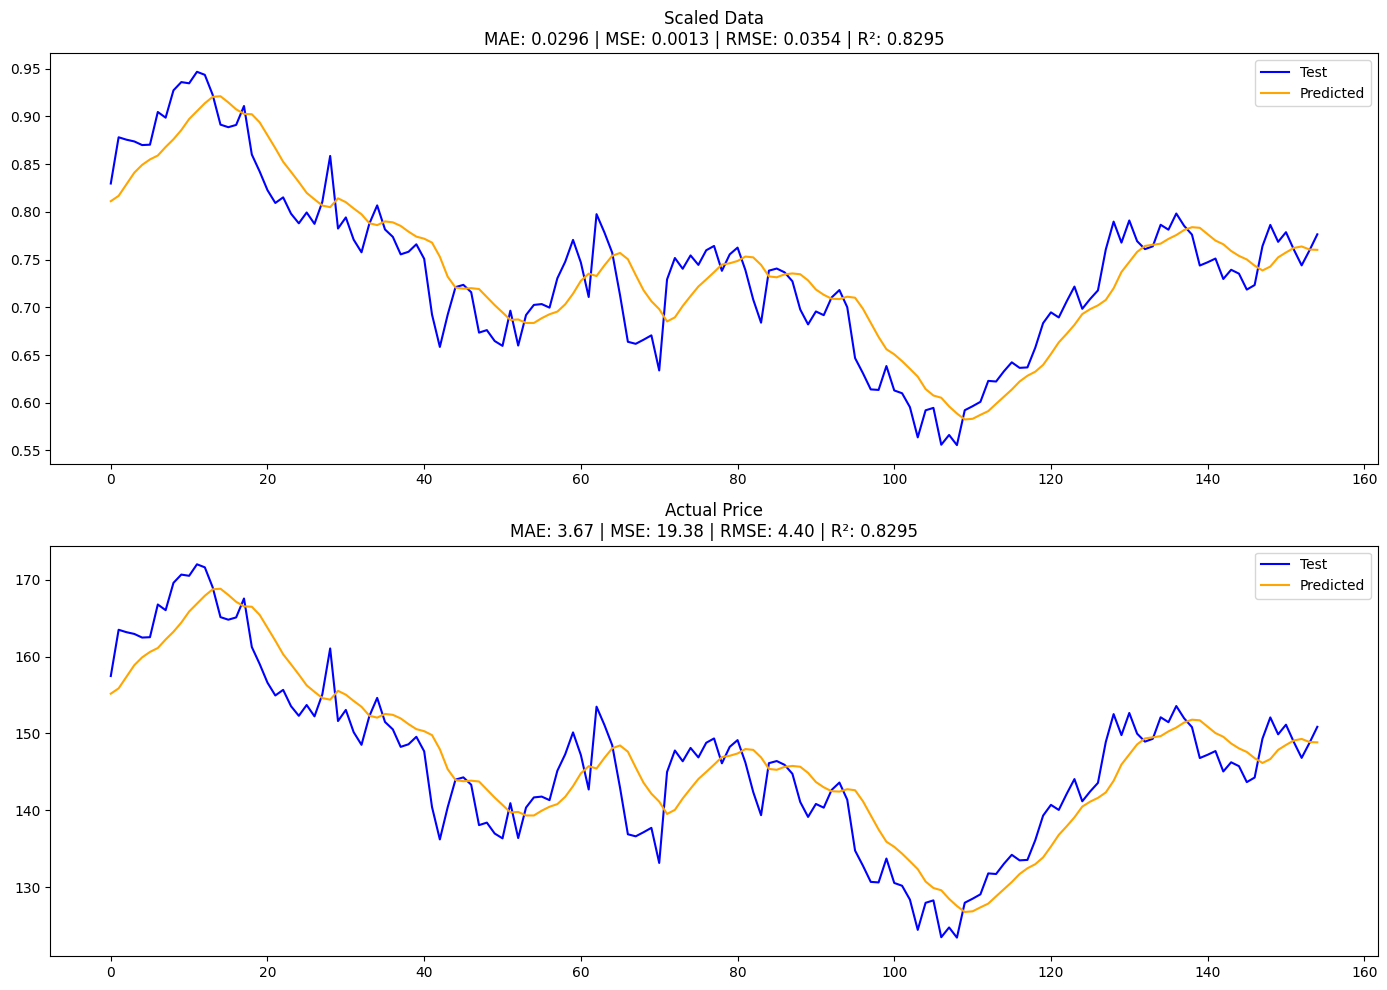

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dropout, Reshape, LSTM, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import math

# ===== Load Data =====
def load_stock_data(ticker='AAPL', start='2020-01-01', end='2023-03-15'):
    df = yf.download(ticker, start=start, end=end)
    return df[['Close']].dropna()

# ===== Preprocess =====
def preprocess(df, time_steps=30):
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(df)

    X, y = [], []
    for i in range(time_steps, len(scaled_data)):
        X.append(scaled_data[i - time_steps:i])
        y.append(scaled_data[i])

    X = np.array(X)
    y = np.array(y)
    X = X.reshape((X.shape[0], X.shape[1], 1, 1))  # for Conv2D input
    return X, y, scaler

# ===== Build CNN-LSTM Model =====
def build_cnn_lstm_model(input_shape):
    model = Sequential()
    model.add(Conv2D(128, (3, 1), activation='relu', input_shape=input_shape))
    model.add(Dropout(0.2))
    model.add(Reshape((input_shape[0] - 2, 128)))  # 30 - (3-1) = 28 time steps
    model.add(LSTM(128))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1))
    return model

# ===== Train =====
def train_model(X_train, y_train, X_val, y_val):
    input_shape = X_train.shape[1:]
    model = build_cnn_lstm_model(input_shape)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

    callbacks = [
        ModelCheckpoint("cnn_lstm_best_weights.h5", save_best_only=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=5, min_lr=1e-5, verbose=1)
    ]

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        callbacks=callbacks,
        verbose=1
    )
    return model

# ===== Evaluasi dan Visualisasi =====
def evaluate_and_plot(model, X_test, y_test, scaler):
    y_pred_scaled = model.predict(X_test)
    y_test_scaled = y_test

    # Evaluasi dalam skala ter-normalisasi
    mse_s = mean_squared_error(y_test_scaled, y_pred_scaled)
    mae_s = mean_absolute_error(y_test_scaled, y_pred_scaled)
    rmse_s = math.sqrt(mse_s)
    r2_s = r2_score(y_test_scaled, y_pred_scaled)

    # Invers transformasi ke harga asli
    y_pred_actual = scaler.inverse_transform(y_pred_scaled)
    y_test_actual = scaler.inverse_transform(y_test_scaled)

    # Evaluasi dalam harga asli
    mse_r = mean_squared_error(y_test_actual, y_pred_actual)
    mae_r = mean_absolute_error(y_test_actual, y_pred_actual)
    rmse_r = math.sqrt(mse_r)
    r2_r = r2_score(y_test_actual, y_pred_actual)

    # Grafik
    plt.figure(figsize=(14, 10))

    # Grafik 1 - Scaled
    plt.subplot(2, 1, 1)
    plt.plot(y_test_scaled, label='Test', color='blue')
    plt.plot(y_pred_scaled, label='Predicted', color='orange')
    plt.title(f"Scaled Data\nMAE: {mae_s:.4f} | MSE: {mse_s:.4f} | RMSE: {rmse_s:.4f} | R²: {r2_s:.4f}")
    plt.legend()

    # Grafik 2 - Actual Price
    plt.subplot(2, 1, 2)
    plt.plot(y_test_actual, label='Test', color='blue')
    plt.plot(y_pred_actual, label='Predicted', color='orange')
    plt.title(f"Actual Price\nMAE: {mae_r:.2f} | MSE: {mse_r:.2f} | RMSE: {rmse_r:.2f} | R²: {r2_r:.4f}")
    plt.legend()

    plt.tight_layout()
    plt.show()

# ===== MAIN =====
if __name__ == '__main__':
    time_steps = 30
    df = load_stock_data(ticker='AAPL')  # bisa ganti BTC-USD untuk Bitcoin
    X, y, scaler = preprocess(df, time_steps)

    split = int(len(X) * 0.8)
    X_train, y_train = X[:split], y[:split]
    X_val, y_val = X[split:], y[split:]

    model = train_model(X_train, y_train, X_val, y_val)
    evaluate_and_plot(model, X_val, y_val, scaler)

/tmp/ipython-input-1897342711.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start='2016-10-30', end='2021-10-30')
[*********************100%***********************]  1 of 1 completed
[I 2025-08-07 04:04:54,591] A new study created in memory with name: no-name-101c2c10-eee8-4b3e-bb81-79a403ca4621
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2025-08-07 04:05:34,604] Trial 0 finished with value: 0.8280529636228564 and parameters: {'time_step': 99, 'lstm_units': 52, 'batch_size': 16, 'lr': 0.00010286324206952024}. Best is trial 0 with value: 0.8280529636228564.
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input


🔍 Best Parameters:
time_step: 72
lstm_units: 127
batch_size: 32
lr: 0.007509543553773495
Best R²: 0.9587
Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - loss: 0.0058
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - loss: 3.7978e-04
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 2.5663e-04
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step - loss: 2.5844e-04
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - loss: 4.7141e-04
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - loss: 3.6338e-04
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - loss: 2.4123e-04
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - loss: 1.9578e-04
Epoch 9/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - loss: 2.1090e-04
Epoch 10/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - loss: 1.3160e-04
Epoch 11/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - loss: 3.7315e-04
Epoch 12/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - loss: 3.2574e-04
Epoch 13/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 2.3033e-04
Epoch 14/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 1.9571e-04
Epoch 15/50
51/51 ━━━━━━━━━

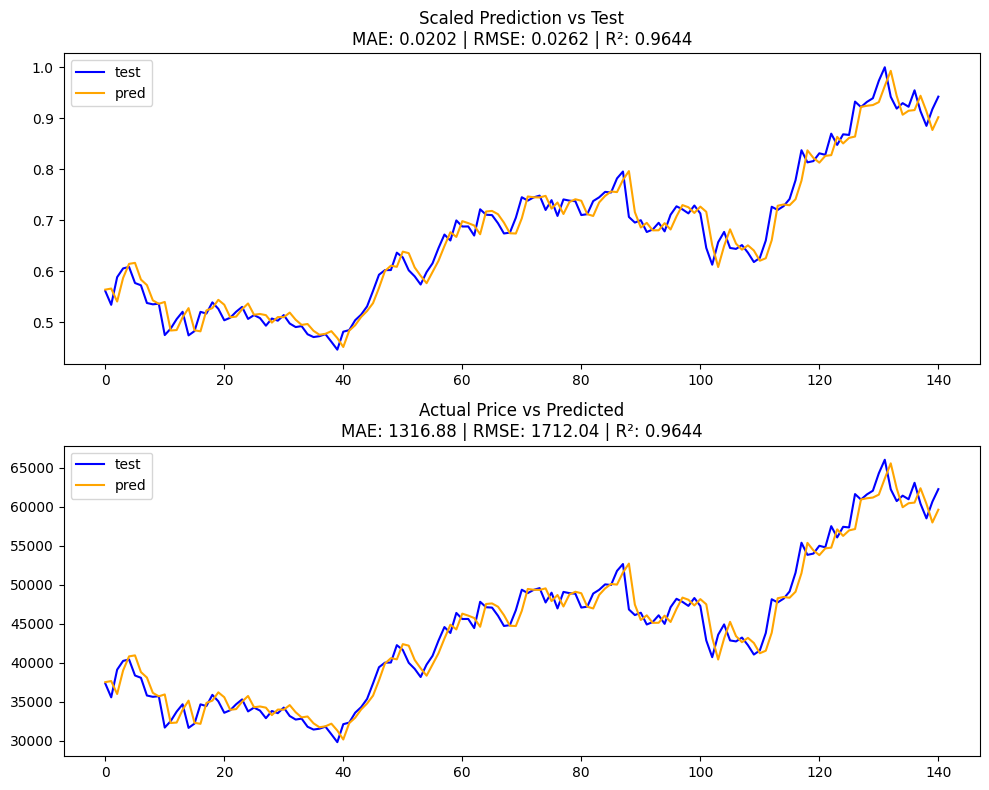

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

# === Step 1: Ambil Data Bitcoin ===
data = yf.download('BTC-USD', start='2016-10-30', end='2021-10-30')
data = data[['Close']]
data = data.interpolate(method='linear')

# === Step 2: Normalisasi ===
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# === Step 3: Fungsi Dataset Time Series ===
def create_dataset(dataset, time_step):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i+time_step])
        y.append(dataset[i+time_step])
    return np.array(X), np.array(y)

# === Step 4: Fungsi Objective untuk Optuna ===
def objective(trial):
    time_step = trial.suggest_int('time_step', 30, 100)
    lstm_units = trial.suggest_int('lstm_units', 32, 128)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)

    X, y = create_dataset(scaled_data, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    train_size = int(len(X) * 0.92)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = Sequential()
    model.add(LSTM(lstm_units, return_sequences=False, input_shape=(X_train.shape[1], 1)))
    model.add(Dense(1))
    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
    model.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=0)

    y_pred = model.predict(X_test, verbose=0)
    r2 = r2_score(y_test, y_pred)
    return r2  # Karena ingin memaksimalkan R²

# === Step 5: Jalankan Optuna ===
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

# === Step 6: Tampilkan Hasil Tuning Terbaik ===
print("\n🔍 Best Parameters:")
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")
print(f"Best R²: {study.best_trial.value:.4f}")

# === Step 7: Bangun Model Final dengan Parameter Terbaik ===
best_params = study.best_trial.params
time_step = best_params['time_step']
lstm_units = best_params['lstm_units']
batch_size = best_params['batch_size']
lr = best_params['lr']

X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.92)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

model = Sequential()
model.add(LSTM(lstm_units, return_sequences=False, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))

model.fit(X_train, y_train, epochs=50, batch_size=batch_size, verbose=1)

# === Step 8: Prediksi dan Evaluasi ===
y_pred = model.predict(X_test)

# Evaluasi (scaled)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Evaluation Metrics (scaled):")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

# Inverse scaling ke harga asli
y_test_inv = scaler.inverse_transform(np.pad(y_test.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant'))[:,0]
y_pred_inv = scaler.inverse_transform(np.pad(y_pred.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant'))[:,0]

mse_inv = mean_squared_error(y_test_inv, y_pred_inv)
mae_inv = mean_absolute_error(y_test_inv, y_pred_inv)
rmse_inv = np.sqrt(mse_inv)
r2_inv = r2_score(y_test_inv, y_pred_inv)

print(f"\n📊 Evaluation Metrics (original price):")
print(f"MAE  : {mae_inv:.2f} USD")
print(f"MSE  : {mse_inv:.2f} USD²")
print(f"RMSE : {rmse_inv:.2f} USD")
print(f"R²   : {r2_inv:.6f}")

# === Step 9: Visualisasi ===
plt.figure(figsize=(10, 8))

# Grafik 1: Skala 0-1
plt.subplot(2, 1, 1)
plt.plot(y_test, label='test', color='blue')
plt.plot(y_pred, label='pred', color='orange')
plt.title(f'Scaled Prediction vs Test\nMAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}')
plt.legend()

# Grafik 2: Harga asli
plt.subplot(2, 1, 2)
plt.plot(y_test_inv, label='test', color='blue')
plt.plot(y_pred_inv, label='pred', color='orange')
plt.title(f'Actual Price vs Predicted\nMAE: {mae_inv:.2f} | RMSE: {rmse_inv:.2f} | R²: {r2_inv:.4f}')
plt.legend()

plt.tight_layout()
plt.show()


/tmp/ipython-input-1897342711.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start='2016-10-30', end='2021-10-30')
[*********************100%***********************]  1 of 1 completed
[I 2025-08-07 04:04:54,591] A new study created in memory with name: no-name-101c2c10-eee8-4b3e-bb81-79a403ca4621
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2025-08-07 04:05:34,604] Trial 0 finished with value: 0.8280529636228564 and parameters: {'time_step': 99, 'lstm_units': 52, 'batch_size': 16, 'lr': 0.00010286324206952024}. Best is trial 0 with value: 0.8280529636228564.
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input


🔍 Best Parameters:
time_step: 72
lstm_units: 127
batch_size: 32
lr: 0.007509543553773495
Best R²: 0.9587
Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - loss: 0.0058
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - loss: 3.7978e-04
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 2.5663e-04
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step - loss: 2.5844e-04
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - loss: 4.7141e-04
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - loss: 3.6338e-04
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - loss: 2.4123e-04
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - loss: 1.9578e-04
Epoch 9/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - loss: 2.1090e-04
Epoch 10/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - loss: 1.3160e-04
Epoch 11/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - loss: 3.7315e-04
Epoch 12/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - loss: 3.2574e-04
Epoch 13/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 2.3033e-04
Epoch 14/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 1.9571e-04
Epoch 15/50
51/51 ━━━━━━━━━

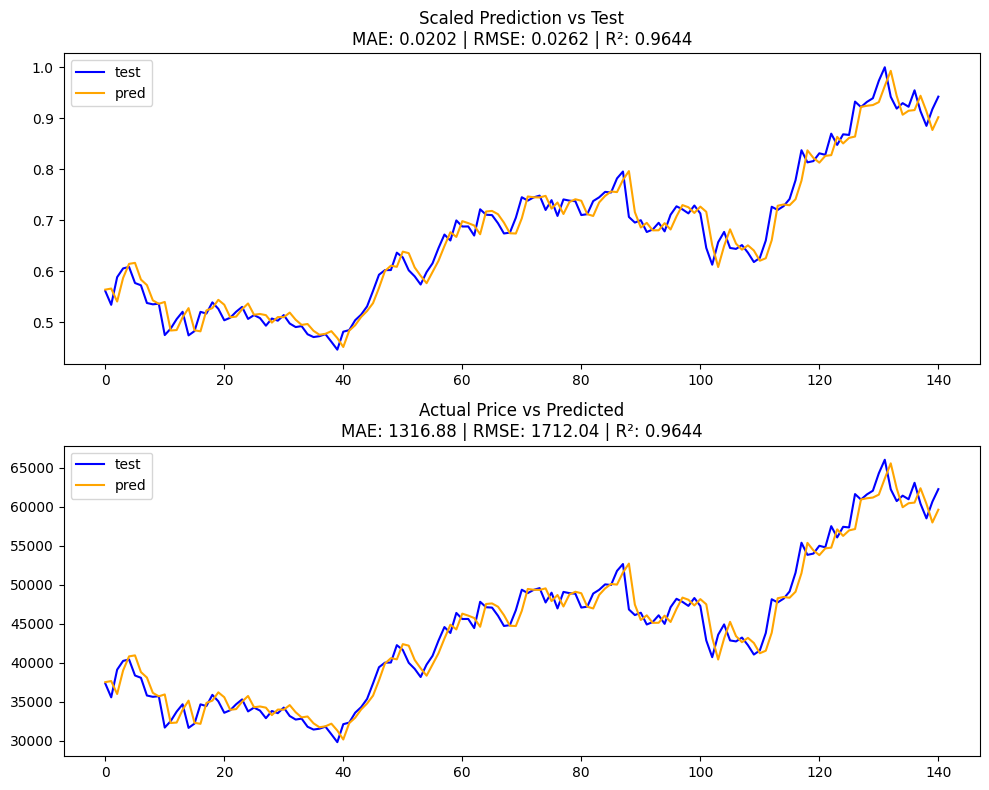

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

# === Step 1: Ambil Data Bitcoin ===
data = yf.download('BTC-USD', start='2016-10-30', end='2021-10-30')
data = data[['Close']]
data = data.interpolate(method='linear')

# === Step 2: Normalisasi ===
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# === Step 3: Fungsi Dataset Time Series ===
def create_dataset(dataset, time_step):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i+time_step])
        y.append(dataset[i+time_step])
    return np.array(X), np.array(y)

# === Step 4: Fungsi Objective untuk Optuna ===
def objective(trial):
    time_step = trial.suggest_int('time_step', 30, 100)
    lstm_units = trial.suggest_int('lstm_units', 32, 128)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)

    X, y = create_dataset(scaled_data, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    train_size = int(len(X) * 0.92)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = Sequential()
    model.add(LSTM(lstm_units, return_sequences=False, input_shape=(X_train.shape[1], 1)))
    model.add(Dense(1))
    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
    model.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=0)

    y_pred = model.predict(X_test, verbose=0)
    r2 = r2_score(y_test, y_pred)
    return r2  # Karena ingin memaksimalkan R²

# === Step 5: Jalankan Optuna ===
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

# === Step 6: Tampilkan Hasil Tuning Terbaik ===
print("\n🔍 Best Parameters:")
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")
print(f"Best R²: {study.best_trial.value:.4f}")

# === Step 7: Bangun Model Final dengan Parameter Terbaik ===
best_params = study.best_trial.params
time_step = best_params['time_step']
lstm_units = best_params['lstm_units']
batch_size = best_params['batch_size']
lr = best_params['lr']

X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.92)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

model = Sequential()
model.add(LSTM(lstm_units, return_sequences=False, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))

model.fit(X_train, y_train, epochs=50, batch_size=batch_size, verbose=1)

# === Step 8: Prediksi dan Evaluasi ===
y_pred = model.predict(X_test)

# Evaluasi (scaled)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Evaluation Metrics (scaled):")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

# Inverse scaling ke harga asli
y_test_inv = scaler.inverse_transform(np.pad(y_test.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant'))[:,0]
y_pred_inv = scaler.inverse_transform(np.pad(y_pred.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant'))[:,0]

mse_inv = mean_squared_error(y_test_inv, y_pred_inv)
mae_inv = mean_absolute_error(y_test_inv, y_pred_inv)
rmse_inv = np.sqrt(mse_inv)
r2_inv = r2_score(y_test_inv, y_pred_inv)

print(f"\n📊 Evaluation Metrics (original price):")
print(f"MAE  : {mae_inv:.2f} USD")
print(f"MSE  : {mse_inv:.2f} USD²")
print(f"RMSE : {rmse_inv:.2f} USD")
print(f"R²   : {r2_inv:.6f}")

# === Step 9: Visualisasi ===
plt.figure(figsize=(10, 8))

# Grafik 1: Skala 0-1
plt.subplot(2, 1, 1)
plt.plot(y_test, label='test', color='blue')
plt.plot(y_pred, label='pred', color='orange')
plt.title(f'Scaled Prediction vs Test\nMAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}')
plt.legend()

# Grafik 2: Harga asli
plt.subplot(2, 1, 2)
plt.plot(y_test_inv, label='test', color='blue')
plt.plot(y_pred_inv, label='pred', color='orange')
plt.title(f'Actual Price vs Predicted\nMAE: {mae_inv:.2f} | RMSE: {rmse_inv:.2f} | R²: {r2_inv:.4f}')
plt.legend()

plt.tight_layout()
plt.show()


/tmp/ipython-input-1897342711.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start='2016-10-30', end='2021-10-30')
[*********************100%***********************]  1 of 1 completed
[I 2025-08-07 04:04:54,591] A new study created in memory with name: no-name-101c2c10-eee8-4b3e-bb81-79a403ca4621
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2025-08-07 04:05:34,604] Trial 0 finished with value: 0.8280529636228564 and parameters: {'time_step': 99, 'lstm_units': 52, 'batch_size': 16, 'lr': 0.00010286324206952024}. Best is trial 0 with value: 0.8280529636228564.
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input


🔍 Best Parameters:
time_step: 72
lstm_units: 127
batch_size: 32
lr: 0.007509543553773495
Best R²: 0.9587
Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - loss: 0.0058
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - loss: 3.7978e-04
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 2.5663e-04
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step - loss: 2.5844e-04
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - loss: 4.7141e-04
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - loss: 3.6338e-04
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - loss: 2.4123e-04
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - loss: 1.9578e-04
Epoch 9/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - loss: 2.1090e-04
Epoch 10/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - loss: 1.3160e-04
Epoch 11/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - loss: 3.7315e-04
Epoch 12/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - loss: 3.2574e-04
Epoch 13/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 2.3033e-04
Epoch 14/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 1.9571e-04
Epoch 15/50
51/51 ━━━━━━━━━

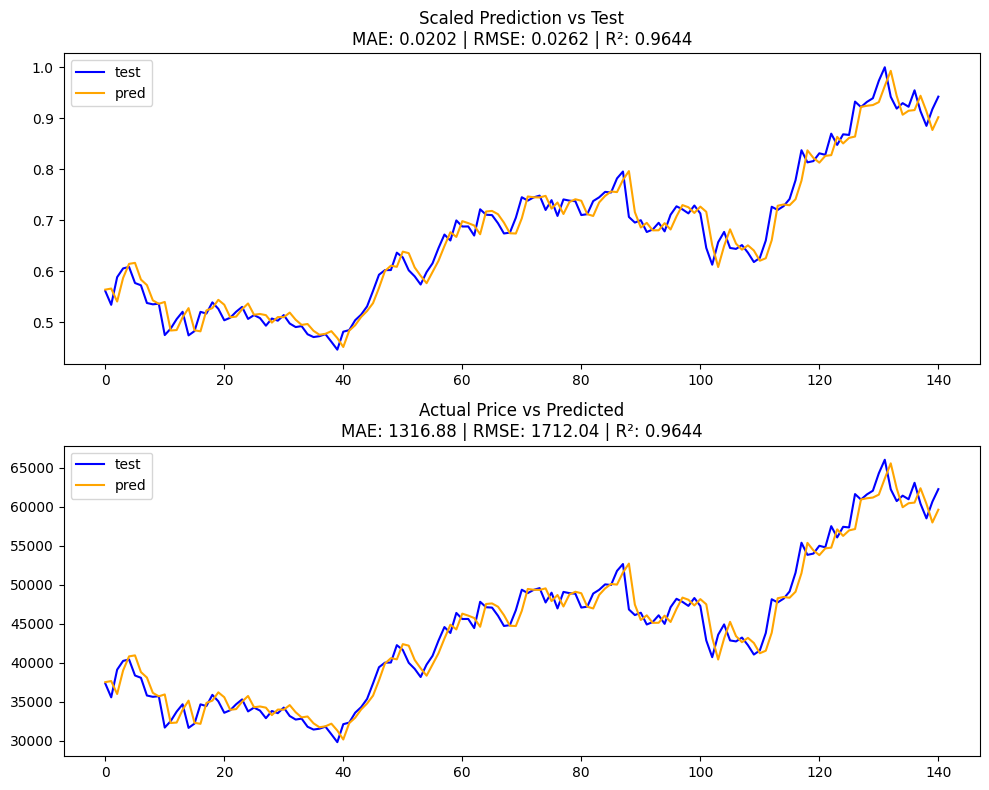

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

# === Step 1: Ambil Data Bitcoin ===
data = yf.download('BTC-USD', start='2016-10-30', end='2021-10-30')
data = data[['Close']]
data = data.interpolate(method='linear')

# === Step 2: Normalisasi ===
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# === Step 3: Fungsi Dataset Time Series ===
def create_dataset(dataset, time_step):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i+time_step])
        y.append(dataset[i+time_step])
    return np.array(X), np.array(y)

# === Step 4: Fungsi Objective untuk Optuna ===
def objective(trial):
    time_step = trial.suggest_int('time_step', 30, 100)
    lstm_units = trial.suggest_int('lstm_units', 32, 128)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)

    X, y = create_dataset(scaled_data, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    train_size = int(len(X) * 0.92)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = Sequential()
    model.add(LSTM(lstm_units, return_sequences=False, input_shape=(X_train.shape[1], 1)))
    model.add(Dense(1))
    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
    model.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=0)

    y_pred = model.predict(X_test, verbose=0)
    r2 = r2_score(y_test, y_pred)
    return r2  # Karena ingin memaksimalkan R²

# === Step 5: Jalankan Optuna ===
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

# === Step 6: Tampilkan Hasil Tuning Terbaik ===
print("\n🔍 Best Parameters:")
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")
print(f"Best R²: {study.best_trial.value:.4f}")

# === Step 7: Bangun Model Final dengan Parameter Terbaik ===
best_params = study.best_trial.params
time_step = best_params['time_step']
lstm_units = best_params['lstm_units']
batch_size = best_params['batch_size']
lr = best_params['lr']

X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.92)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

model = Sequential()
model.add(LSTM(lstm_units, return_sequences=False, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))

model.fit(X_train, y_train, epochs=50, batch_size=batch_size, verbose=1)

# === Step 8: Prediksi dan Evaluasi ===
y_pred = model.predict(X_test)

# Evaluasi (scaled)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Evaluation Metrics (scaled):")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

# Inverse scaling ke harga asli
y_test_inv = scaler.inverse_transform(np.pad(y_test.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant'))[:,0]
y_pred_inv = scaler.inverse_transform(np.pad(y_pred.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant'))[:,0]

mse_inv = mean_squared_error(y_test_inv, y_pred_inv)
mae_inv = mean_absolute_error(y_test_inv, y_pred_inv)
rmse_inv = np.sqrt(mse_inv)
r2_inv = r2_score(y_test_inv, y_pred_inv)

print(f"\n📊 Evaluation Metrics (original price):")
print(f"MAE  : {mae_inv:.2f} USD")
print(f"MSE  : {mse_inv:.2f} USD²")
print(f"RMSE : {rmse_inv:.2f} USD")
print(f"R²   : {r2_inv:.6f}")

# === Step 9: Visualisasi ===
plt.figure(figsize=(10, 8))

# Grafik 1: Skala 0-1
plt.subplot(2, 1, 1)
plt.plot(y_test, label='test', color='blue')
plt.plot(y_pred, label='pred', color='orange')
plt.title(f'Scaled Prediction vs Test\nMAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}')
plt.legend()

# Grafik 2: Harga asli
plt.subplot(2, 1, 2)
plt.plot(y_test_inv, label='test', color='blue')
plt.plot(y_pred_inv, label='pred', color='orange')
plt.title(f'Actual Price vs Predicted\nMAE: {mae_inv:.2f} | RMSE: {rmse_inv:.2f} | R²: {r2_inv:.4f}')
plt.legend()

plt.tight_layout()
plt.show()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.4/247.4 kB 18.1 MB/s eta 0:00:00


/tmp/ipython-input-3058523282.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start='2014-10-30', end='2023-10-30')
[*********************100%***********************]  1 of 1 completed
[I 2025-08-28 09:09:13,326] A new study created in memory with name: no-name-71c686af-8ac1-4cd4-a5f0-d82ccbbe6520
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2025-08-28 09:10:17,823] Trial 0 finished with value: 0.8812289286199889 and parameters: {'time_step': 68, 'lstm_units': 120, 'gru_units': 110, 'dropout': 0.46193554062171904, 'batch_size': 64, 'lr': 4.165030744120143e-05}. Best is trial 0 with value: 0.8812289286199889.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199


🔍 Best Parameters:
time_step: 45
lstm_units: 75
gru_units: 58
dropout: 0.1366844755484502
batch_size: 16
lr: 0.00023396013220374292
Best R²: 0.9562
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


173/173 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.0114
Epoch 2/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0013
Epoch 3/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0010
Epoch 4/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 9.2352e-04
Epoch 5/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 8.7268e-04
Epoch 6/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 8.4709e-04
Epoch 7/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 8.0088e-04
Epoch 8/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 7.4046e-04
Epoch 9/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 6.4085e-04
Epoch 10/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 8.2988e-04
Epoch 11/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 5.9666e-04
Epoch 12/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 6.5060e-04
Epoch 13/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 5.3947e-04
Epoch 14/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 6.0145e-04
Epoch 15/5

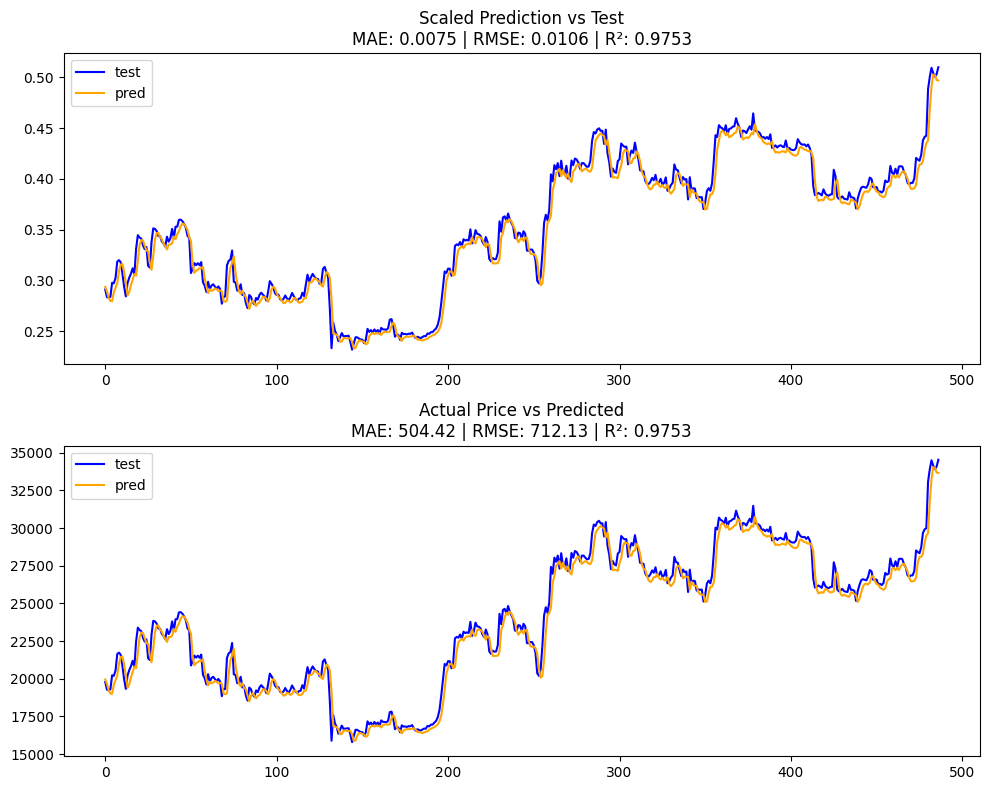

In [ ]:
!pip install optuna
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# === Step 1: Ambil Data Bitcoin ===
data = yf.download('BTC-USD', start='2014-10-30', end='2023-10-30')
data = data[['Close']]
data = data.interpolate(method='linear')

# === Step 2: Normalisasi ===
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# === Step 3: Fungsi Dataset Time Series ===
def create_dataset(dataset, time_step):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i+time_step])
        y.append(dataset[i+time_step])
    return np.array(X), np.array(y)

# === Step 4: Fungsi Objective untuk Optuna ===
def objective(trial):
    time_step = trial.suggest_int('time_step', 30, 100)
    lstm_units = trial.suggest_int('lstm_units', 32, 128)
    gru_units = trial.suggest_int('gru_units', 32, 128)
    dropout_rate = trial.suggest_float('dropout', 0.1, 0.5)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)

    X, y = create_dataset(scaled_data, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    train_size = int(len(X) * 0.85)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = Sequential()
    model.add(LSTM(lstm_units, return_sequences=True, input_shape=(X_train.shape[1], 1)))
    model.add(GRU(gru_units, return_sequences=False))
    model.add(Dropout(dropout_rate))
    model.add(Dense(1))

    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
    model.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=0)

    y_pred = model.predict(X_test, verbose=0)
    r2 = r2_score(y_test, y_pred)
    return r2  # Karena ingin memaksimalkan R²

# === Step 5: Jalankan Optuna ===
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

# === Step 6: Tampilkan Hasil Tuning Terbaik ===
print("\n🔍 Best Parameters:")
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")
print(f"Best R²: {study.best_trial.value:.4f}")

# === Step 7: Bangun Model Final dengan Parameter Terbaik ===
best_params = study.best_trial.params
time_step = best_params['time_step']
lstm_units = best_params['lstm_units']
gru_units = best_params['gru_units']
dropout_rate = best_params['dropout']
batch_size = best_params['batch_size']
lr = best_params['lr']

X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.85)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

model = Sequential()
model.add(LSTM(lstm_units, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(GRU(gru_units, return_sequences=False))
model.add(Dropout(dropout_rate))
model.add(Dense(1))

model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
model.fit(X_train, y_train, epochs=50, batch_size=batch_size, verbose=1)

# === Step 8: Prediksi dan Evaluasi ===
y_pred = model.predict(X_test)

# Evaluasi (scaled)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Evaluation Metrics (scaled):")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

# Inverse scaling ke harga asli
y_test_inv = scaler.inverse_transform(
    np.pad(y_test.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant')
)[:,0]
y_pred_inv = scaler.inverse_transform(
    np.pad(y_pred.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant')
)[:,0]

mse_inv = mean_squared_error(y_test_inv, y_pred_inv)
mae_inv = mean_absolute_error(y_test_inv, y_pred_inv)
rmse_inv = np.sqrt(mse_inv)
r2_inv = r2_score(y_test_inv, y_pred_inv)

print(f"\n📊 Evaluation Metrics (original price):")
print(f"MAE  : {mae_inv:.2f} USD")
print(f"MSE  : {mse_inv:.2f} USD²")
print(f"RMSE : {rmse_inv:.2f} USD")
print(f"R²   : {r2_inv:.6f}")

# === Step 9: Visualisasi ===
plt.figure(figsize=(10, 8))

# Grafik 1: Skala 0-1
plt.subplot(2, 1, 1)
plt.plot(y_test, label='test', color='blue')
plt.plot(y_pred, label='pred', color='orange')
plt.title(f'Scaled Prediction vs Test\nMAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}')
plt.legend()

# Grafik 2: Harga asli
plt.subplot(2, 1, 2)
plt.plot(y_test_inv, label='test', color='blue')
plt.plot(y_pred_inv, label='pred', color='orange')
plt.title(f'Actual Price vs Predicted\nMAE: {mae_inv:.2f} | RMSE: {rmse_inv:.2f} | R²: {r2_inv:.4f}')
plt.legend()

plt.tight_layout()
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 8.8 MB/s eta 0:00:00


/tmp/ipython-input-4029236944.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start='2014-10-01', end='2023-02-01')
[*********************100%***********************]  1 of 1 completed
[I 2025-10-17 14:34:58,379] A new study created in memory with name: no-name-677019ac-7963-4843-b8a0-2a2489e0190f
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2025-10-17 14:36:00,563] Trial 0 finished with value: 0.9841427029640003 and parameters: {'time_step': 43, 'lstm_units': 67, 'gru_units': 105, 'dropout': 0.17283419764017294, 'batch_size': 16, 'lr': 0.00039398756800235836}. Best is trial 0 with value: 0.9841427029640003.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199


🔍 Best Parameters:
time_step: 99
lstm_units: 123
gru_units: 116
dropout: 0.3004165115080417
batch_size: 64
lr: 0.004978994670523453
Best R²: 0.9914
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 12s 376ms/step - loss: 0.0058
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 376ms/step - loss: 1.7978e-04
Epoch 3/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 303ms/step - loss: 9.0442e-05
Epoch 4/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 382ms/step - loss: 1.1408e-04
Epoch 5/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 370ms/step - loss: 9.8666e-05
Epoch 6/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 305ms/step - loss: 1.0109e-04
Epoch 7/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 308ms/step - loss: 6.1790e-05
Epoch 8/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 376ms/step - loss: 5.4465e-05
Epoch 9/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 308ms/step - loss: 6.7897e-05
Epoch 10/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 359ms/step - loss: 8.3788e-05
Epoch 11/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 374ms/step - loss: 3.3797e-04
Epoch 12/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 306ms/step - loss: 1.2298e-04
Epoch 13/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 374ms/step - loss: 5.3696e-05
Epoch 14/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 375ms/step - loss: 5.4165e-05
Epoch 15/50
2

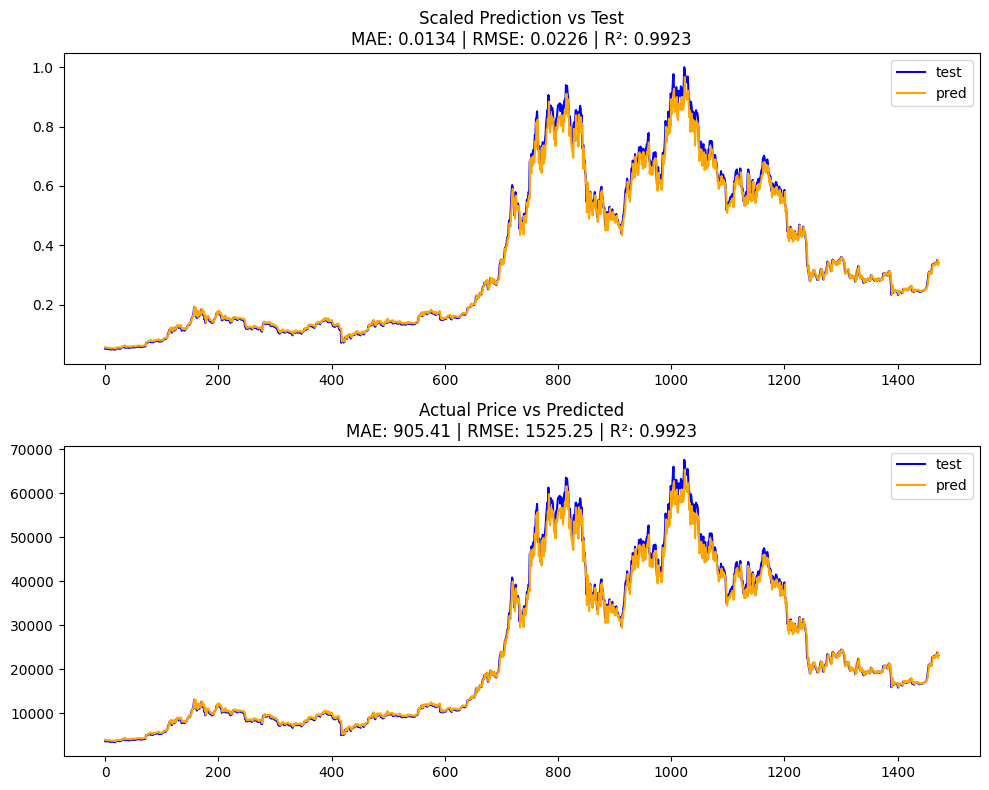

In [ ]:
!pip install optuna
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# === Step 1: Ambil Data Bitcoin ===
data = yf.download('BTC-USD', start='2014-10-01', end='2023-02-01')
data = data[['Close']]
data = data.interpolate(method='linear')

# === Step 2: Normalisasi ===
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# === Step 3: Fungsi Dataset Time Series ===
def create_dataset(dataset, time_step):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i+time_step])
        y.append(dataset[i+time_step])
    return np.array(X), np.array(y)

# === Step 4: Fungsi Objective untuk Optuna ===
def objective(trial):
    time_step = trial.suggest_int('time_step', 30, 100)
    lstm_units = trial.suggest_int('lstm_units', 32, 128)
    gru_units = trial.suggest_int('gru_units', 32, 128)
    dropout_rate = trial.suggest_float('dropout', 0.1, 0.5)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)

    X, y = create_dataset(scaled_data, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    train_size = int(len(X) * 0.5)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = Sequential()
    model.add(LSTM(lstm_units, return_sequences=True, input_shape=(X_train.shape[1], 1)))
    model.add(GRU(gru_units, return_sequences=False))
    model.add(Dropout(dropout_rate))
    model.add(Dense(1))

    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
    model.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=0)

    y_pred = model.predict(X_test, verbose=0)
    r2 = r2_score(y_test, y_pred)
    return r2  # Karena ingin memaksimalkan R²

# === Step 5: Jalankan Optuna ===
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

# === Step 6: Tampilkan Hasil Tuning Terbaik ===
print("\n🔍 Best Parameters:")
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")
print(f"Best R²: {study.best_trial.value:.4f}")

# === Step 7: Bangun Model Final dengan Parameter Terbaik ===
best_params = study.best_trial.params
time_step = best_params['time_step']
lstm_units = best_params['lstm_units']
gru_units = best_params['gru_units']
dropout_rate = best_params['dropout']
batch_size = best_params['batch_size']
lr = best_params['lr']

X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.5)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

model = Sequential()
model.add(LSTM(lstm_units, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(GRU(gru_units, return_sequences=False))
model.add(Dropout(dropout_rate))
model.add(Dense(1))

model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
model.fit(X_train, y_train, epochs=50, batch_size=batch_size, verbose=1)

# === Step 8: Prediksi dan Evaluasi ===
y_pred = model.predict(X_test)

# Evaluasi (scaled)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Evaluation Metrics (scaled):")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

# Inverse scaling ke harga asli
y_test_inv = scaler.inverse_transform(
    np.pad(y_test.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant')
)[:,0]
y_pred_inv = scaler.inverse_transform(
    np.pad(y_pred.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant')
)[:,0]

mse_inv = mean_squared_error(y_test_inv, y_pred_inv)
mae_inv = mean_absolute_error(y_test_inv, y_pred_inv)
rmse_inv = np.sqrt(mse_inv)
r2_inv = r2_score(y_test_inv, y_pred_inv)

print(f"\n📊 Evaluation Metrics (original price):")
print(f"MAE  : {mae_inv:.2f} USD")
print(f"MSE  : {mse_inv:.2f} USD²")
print(f"RMSE : {rmse_inv:.2f} USD")
print(f"R²   : {r2_inv:.6f}")

# === Step 9: Visualisasi ===
plt.figure(figsize=(10, 8))

# Grafik 1: Skala 0-1
plt.subplot(2, 1, 1)
plt.plot(y_test, label='test', color='blue')
plt.plot(y_pred, label='pred', color='orange')
plt.title(f'Scaled Prediction vs Test\nMAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}')
plt.legend()

# Grafik 2: Harga asli
plt.subplot(2, 1, 2)
plt.plot(y_test_inv, label='test', color='blue')
plt.plot(y_pred_inv, label='pred', color='orange')
plt.title(f'Actual Price vs Predicted\nMAE: {mae_inv:.2f} | RMSE: {rmse_inv:.2f} | R²: {r2_inv:.4f}')
plt.legend()

plt.tight_layout()
plt.show()

/tmp/ipython-input-755819517.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start='2014-10-01', end='2023-02-01')
[*********************100%***********************]  1 of 1 completed
[I 2025-10-19 12:28:35,192] A new study created in memory with name: no-name-d1a2c897-ddcd-4fcc-9947-2c045cbf4ef6
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2025-10-19 12:29:26,701] Trial 0 finished with value: 0.9795217324150822 and parameters: {'time_step': 47, 'lstm_units': 41, 'gru_units': 68, 'dropout': 0.4451592290666665, 'batch_size': 16, 'lr': 0.000264541311044649}. Best is trial 0 with value: 0.9795217324150822.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: Use


🔍 Best Parameters:
time_step: 83
lstm_units: 34
gru_units: 73
dropout: 0.15382008261537214
batch_size: 16
lr: 0.0020560690462478226
Best R²: 0.9878
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - loss: 5.2500e-06
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 0.0020
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - loss: 8.5508e-05
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - loss: 2.9589e-04
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - loss: 6.8166e-04
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 6.7496e-04
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 2.5476e-04
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 2.4341e-05
Epoch 9/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 6.8322e-05
Epoch 10/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 2.3500e-04
Epoch 11/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - loss: 2.1418e-04
Epoch 12/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 1.5834e-04
Epoch 13/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - loss: 2.1205e-05
Epoch 14/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - loss: 4.2160e-05
Epoch 15/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/s

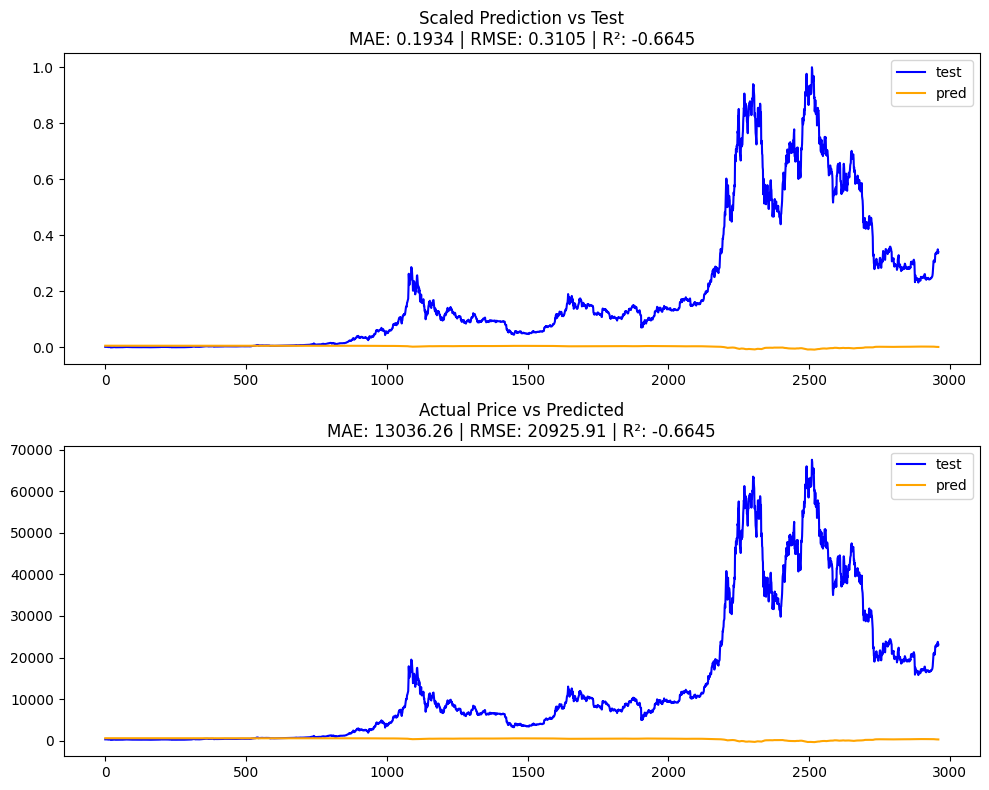

In [ ]:
!pip install optuna
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# === Step 1: Ambil Data Bitcoin ===
data = yf.download('BTC-USD', start='2014-10-01', end='2023-02-01')
data = data[['Close']]
data = data.interpolate(method='linear')

# === Step 2: Normalisasi ===
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# === Step 3: Fungsi Dataset Time Series ===
def create_dataset(dataset, time_step):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i+time_step])
        y.append(dataset[i+time_step])
    return np.array(X), np.array(y)

# === Step 4: Fungsi Objective untuk Optuna ===
def objective(trial):
    time_step = trial.suggest_int('time_step', 30, 100)
    lstm_units = trial.suggest_int('lstm_units', 32, 128)
    gru_units = trial.suggest_int('gru_units', 32, 128)
    dropout_rate = trial.suggest_float('dropout', 0.1, 0.5)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)

    X, y = create_dataset(scaled_data, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    train_size = int(len(X) * 0.5)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = Sequential()
    model.add(LSTM(lstm_units, return_sequences=True, input_shape=(X_train.shape[1], 1)))
    model.add(GRU(gru_units, return_sequences=False))
    model.add(Dropout(dropout_rate))
    model.add(Dense(1))

    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
    model.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=0)

    y_pred = model.predict(X_test, verbose=0)
    r2 = r2_score(y_test, y_pred)
    return r2  # Karena ingin memaksimalkan R²

# === Step 5: Jalankan Optuna ===
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

# === Step 6: Tampilkan Hasil Tuning Terbaik ===
print("\n🔍 Best Parameters:")
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")
print(f"Best R²: {study.best_trial.value:.4f}")

# === Step 7: Bangun Model Final dengan Parameter Terbaik ===
best_params = study.best_trial.params
time_step = best_params['time_step']
lstm_units = best_params['lstm_units']
gru_units = best_params['gru_units']
dropout_rate = best_params['dropout']
batch_size = best_params['batch_size']
lr = best_params['lr']

X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.001)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

model = Sequential()
model.add(LSTM(lstm_units, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(GRU(gru_units, return_sequences=False))
model.add(Dropout(dropout_rate))
model.add(Dense(1))

model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
model.fit(X_train, y_train, epochs=50, batch_size=batch_size, verbose=1)

# === Step 8: Prediksi dan Evaluasi ===
y_pred = model.predict(X_test)

# Evaluasi (scaled)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Evaluation Metrics (scaled):")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

# Inverse scaling ke harga asli
y_test_inv = scaler.inverse_transform(
    np.pad(y_test.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant')
)[:,0]
y_pred_inv = scaler.inverse_transform(
    np.pad(y_pred.reshape(-1,1), ((0,0),(0,data.shape[1]-1)), 'constant')
)[:,0]

mse_inv = mean_squared_error(y_test_inv, y_pred_inv)
mae_inv = mean_absolute_error(y_test_inv, y_pred_inv)
rmse_inv = np.sqrt(mse_inv)
r2_inv = r2_score(y_test_inv, y_pred_inv)

print(f"\n📊 Evaluation Metrics (original price):")
print(f"MAE  : {mae_inv:.2f} USD")
print(f"MSE  : {mse_inv:.2f} USD²")
print(f"RMSE : {rmse_inv:.2f} USD")
print(f"R²   : {r2_inv:.6f}")

# === Step 9: Visualisasi ===
plt.figure(figsize=(10, 8))

# Grafik 1: Skala 0-1
plt.subplot(2, 1, 1)
plt.plot(y_test, label='test', color='blue')
plt.plot(y_pred, label='pred', color='orange')
plt.title(f'Scaled Prediction vs Test\nMAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}')
plt.legend()

# Grafik 2: Harga asli
plt.subplot(2, 1, 2)
plt.plot(y_test_inv, label='test', color='blue')
plt.plot(y_pred_inv, label='pred', color='orange')
plt.title(f'Actual Price vs Predicted\nMAE: {mae_inv:.2f} | RMSE: {rmse_inv:.2f} | R²: {r2_inv:.4f}')
plt.legend()

plt.tight_layout()
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 17.2 MB/s eta 0:00:00


/tmp/ipykernel_3446/3158589922.py:24: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start='2014-10-01', end='2023-02-01')
[*********************100%***********************]  1 of 1 completed
[I 2026-04-12 15:19:40,434] A new study created in memory with name: no-name-28805b6a-697a-4bd5-9b8d-4a7e519cefca
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2026-04-12 15:20:15,277] Trial 0 finished with value: 0.9752471972916751 and parameters: {'time_step': 70, 'lstm_units': 48, 'dropout': 0.22522920083640274, 'batch_size': 16, 'lr': 0.002174056033924148}. Best is trial 0 with value: 0.9752471972916751.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do n


🔍 Best Parameters:
time_step: 61
lstm_units: 44
dropout: 0.4258768661118285
batch_size: 64
lr: 0.0011521681774458788
Best R²: 0.9802
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0127
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0034
Epoch 3/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0024
Epoch 4/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0020
Epoch 5/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0018
Epoch 6/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0016
Epoch 7/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0017
Epoch 8/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0016
Epoch 9/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0018
Epoch 10/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0016
Epoch 11/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0015
Epoch 12/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0017
Epoch 13/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0015
Epoch 14/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0015
Epoch 15/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0014
Epoch 16/50
40/

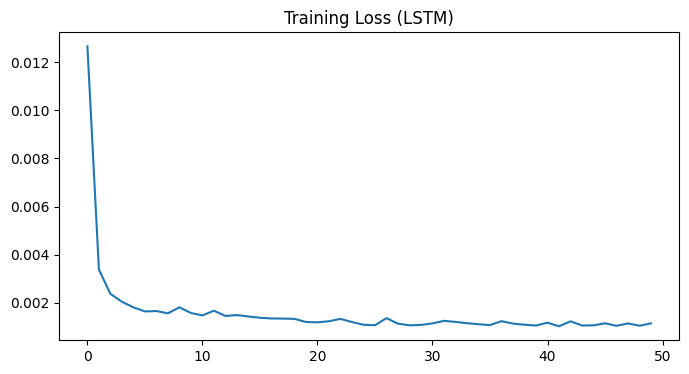

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

📊 Evaluation (Scaled):
MAE  : 0.020362
RMSE : 0.027477
R²   : 0.978762


In [ ]:
!pip install optuna yfinance --quiet

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# === Step 1: Ambil Data Bitcoin ===
data = yf.download('BTC-USD', start='2014-10-01', end='2023-02-01')
data = data[['Close']]
data = data.interpolate(method='linear')

# === Step 2: Normalisasi ===
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data.values)

# === Step 3: Dataset Time Series ===
def create_dataset(dataset, time_step=60):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i+time_step])
        y.append(dataset[i+time_step])
    return np.array(X), np.array(y)

# === Step 4: Objective Optuna ===
def objective(trial):
    time_step = trial.suggest_int('time_step', 30, 100)
    lstm_units = trial.suggest_int('lstm_units', 32, 128)
    dropout_rate = trial.suggest_float('dropout', 0.1, 0.5)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)

    X, y = create_dataset(scaled_data, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    train_size = int(len(X) * 0.85)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = Sequential()
    model.add(LSTM(lstm_units, input_shape=(X_train.shape[1], 1)))
    model.add(Dropout(dropout_rate))
    model.add(Dense(1))

    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=lr))
    model.fit(X_train, y_train, epochs=10, batch_size=batch_size, verbose=0)

    y_pred = model.predict(X_test, verbose=0)
    return r2_score(y_test, y_pred)

# === Step 5: Optuna ===
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

print("\n🔍 Best Parameters:")
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")
print(f"Best R²: {study.best_trial.value:.4f}")

# === Step 6: Model Final ===
best_params = study.best_trial.params

X, y = create_dataset(scaled_data, best_params['time_step'])
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.85)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

model = Sequential()
model.add(LSTM(best_params['lstm_units'], input_shape=(X_train.shape[1], 1)))
model.add(Dropout(best_params['dropout']))
model.add(Dense(1))

model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=best_params['lr']))

history = model.fit(X_train, y_train, epochs=50, batch_size=best_params['batch_size'], verbose=1)

# === Step 7: Visualisasi Loss ===
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'])
plt.title("Training Loss (LSTM)")
plt.show()

# === Step 8: Prediksi ===
y_pred = model.predict(X_test)

# Evaluasi
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n📊 Evaluation (Scaled):")
print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")
